# What an Encoding Knows
## A runnable companion to the Witness study

This notebook follows Witness from one encoded page to the paged results. It
stands on its own: mechanisms run against the current Rust implementation, and
empirical figures load the canonical evidence behind the claim manifest.

The central question is simple:

> When encoded bytes justify a fact about their values, can a query use that fact
> without reading so much data that the opportunity disappears?

The notebook answers that question in four passes:

1. **Mechanism (§§1–3):** one small table becomes real serialized pages, typed
   facts, an authorized plan, physical reads, and an exact answer.
2. **Evidence on one page (§§4–6):** canonical study CSVs answer availability,
   effect, price, controls, and two further plans, with their statistical scope.
3. **Paged columns (§7):** facts planned page by page against an exact stored zone
   map on one executor, faulty statistics, the plan checker, deletes, and threads.
4. **Boundary (§§8–10):** related systems, limits, and the decision rule, then the
   reproduction chain.

Toy values are labelled as examples. Source links appear where they help a reader
inspect an implementation detail. Every empirical number is loaded from committed
claim-bearing results. Missing evidence is a hard error: this notebook never
substitutes synthetic rows for measured results.


In [1]:
# Environment, canonical evidence, and the live Rust bridge.
from __future__ import annotations

import csv, json, math, re, subprocess, textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "Cargo.toml").is_file() and (p / "experiments/results").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Run this notebook from the Witness repository or docs/notebooks/")

RESULTS, GENERATED = ROOT / "experiments/results", ROOT / "docs/generated"
required = [
    RESULTS / "claim_manifest.csv",
    RESULTS / "predicate_pipeline/source_summary.csv",
    RESULTS / "invariant_census/sources.csv",
    RESULTS / "certificate_study/summary.csv",
    RESULTS / "real_access/storage_scan.csv",
    RESULTS / "paged_study/queries.csv",
    RESULTS / "paged_study/faults.csv",
    RESULTS / "paged_study/checker.csv",
    RESULTS / "paged_study/deletes.csv",
    GENERATED / "example_values.csv",
    GENERATED / "witness_layout.csv",
    GENERATED / "format_artifacts.csv",
    GENERATED / "query_paths.csv",
]
missing = [str(p.relative_to(ROOT)) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError("Canonical evidence is incomplete:\n  " + "\n  ".join(missing))

build = subprocess.run(
    ["cargo", "build", "--release", "--locked", "--features", "experiment",
     "--bin", "witness_explore"], cwd=ROOT, capture_output=True, text=True,
)
if build.returncode:
    raise RuntimeError(build.stderr)
EXPLORE = ROOT / "target/release/witness_explore"

def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))

CLAIMS = {r["claim"]: r["value"] for r in read_csv(RESULTS / "claim_manifest.csv")}

def claim(name):
    if name not in CLAIMS:
        raise KeyError(f"claim manifest has no {name}")
    return CLAIMS[name]

def witness(subcommand, **payload):
    run = subprocess.run(
        [str(EXPLORE), subcommand, json.dumps(payload)],
        cwd=ROOT, capture_output=True, text=True,
    )
    if run.returncode:
        raise RuntimeError(run.stderr.strip() or f"witness_explore {subcommand} failed")
    return json.loads(run.stdout)

print(f"repository       {ROOT}")
print(f"claims           {len(CLAIMS)} canonical values")
print(f"crate/fingerprint {claim('WitCrateVersion')} / {claim('WitRuleFingerprint')}")
print("Rust bridge      rebuilt from the current source")


repository       /data/experiments/git_repos/witness
claims           449 canonical values
crate/fingerprint 0.2.0 / 0x99a7c98c6d7ef569
Rust bridge      rebuilt from the current source


In [2]:
# Shared visual language. These helpers render evidence; they do not implement codecs.
BLUE, ORANGE, TEAL, RED = "#2A78D6", "#E66A32", "#188977", "#C2413B"
INK, MUTED, GRID, PALE = "#18181B", "#52525B", "#D4D4D8", "#F4F4F5"

mpl.rcParams.update({
    "figure.dpi": 125, "savefig.dpi": 125, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.alpha": 0.55, "grid.linewidth": 0.7, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False,
})

def parse_plot(name):
    points = re.findall(r"\(([^,]+),([^\)]+)\)", claim(name))
    return np.array([float(x) for x, _ in points]), np.array([float(y) for _, y in points])

def standard_median(values):
    values = sorted(values)
    middle = len(values) // 2
    return values[middle] if len(values) % 2 else (values[middle - 1] + values[middle]) / 2

def box(ax, xy, width, height, title, body, face="white", edge=GRID, title_color=INK):
    patch = mpl.patches.FancyBboxPatch(
        xy, width, height, boxstyle="round,pad=0.012,rounding_size=0.018",
        linewidth=1.25, edgecolor=edge, facecolor=face,
    )
    ax.add_patch(patch)
    ax.text(xy[0] + width / 2, xy[1] + height * 0.68, title,
            ha="center", va="center", weight="bold", color=title_color)
    ax.text(xy[0] + width / 2, xy[1] + height * 0.32, body,
            ha="center", va="center", fontsize=8.3, color=MUTED, linespacing=1.3)

print("visual helpers   ready")


visual helpers   ready


## How the pieces connect

The argument and implementation follow one path. Values become a serialized page;
the page's decoder, layout, and descriptor yield facts; facts authorize a plan;
the runtime closes that plan over physical bytes; studies then measure where the
combination helps and where it falls back.


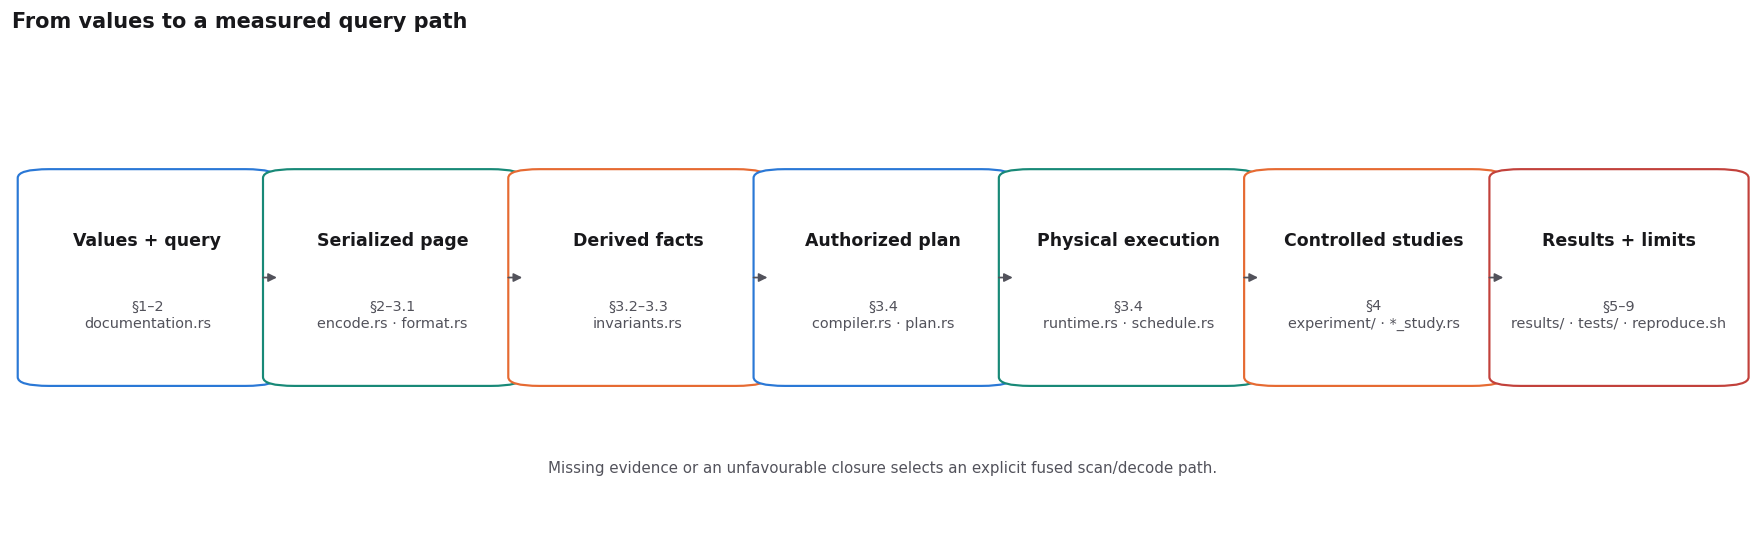

All referenced source and result paths exist in the current tree.


In [3]:
steps = [
    ("Values + query", "§1–2\ndocumentation.rs", BLUE),
    ("Serialized page", "§2–3.1\nencode.rs · format.rs", TEAL),
    ("Derived facts", "§3.2–3.3\ninvariants.rs", ORANGE),
    ("Authorized plan", "§3.4\ncompiler.rs · plan.rs", BLUE),
    ("Physical execution", "§3.4\nruntime.rs · schedule.rs", TEAL),
    ("Controlled studies", "§4\nexperiment/ · *_study.rs", ORANGE),
    ("Results + limits", "§5–9\nresults/ · tests/ · reproduce.sh", RED),
]
fig, ax = plt.subplots(figsize=(14, 4.2), constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
for i, (title, body, colour) in enumerate(steps):
    x = 0.015 + i * 0.141
    box(ax, (x, 0.30), 0.125, 0.42, title, body, "white", colour)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 0.139, 0.51), xytext=(x + 0.127, 0.51),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.0))
ax.text(0.50, 0.11,
        "Missing evidence or an unfavourable closure selects an explicit fused scan/decode path.",
        ha="center", fontsize=8.7, color=MUTED)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("From values to a measured query path", loc="left", weight="bold")
plt.show()

paths = [
    "src/access_compiler/encode.rs", "src/access_compiler/format.rs",
    "src/access_compiler/decoder.rs", "src/access_compiler/layout.rs",
    "src/access_compiler/invariants.rs", "src/access_compiler/compiler.rs",
    "src/access_compiler/plan.rs", "src/access_compiler/runtime.rs",
    "src/experiment", "experiments/results", "tests", "reproduce.sh",
]
assert all((ROOT / p).exists() for p in paths)
print("All referenced source and result paths exist in the current tree.")


## 1. One query, from rows to bytes

Descriptions of the method begin abstractly; the notebook begins physically. Rust's documentation
generator produces the 16-row table below and serializes every column into the
same page format used by the study. The size is intentionally tiny so every value,
field, offset, and answer can be inspected. It is **not** a compression benchmark:
fixed headers dominate sixteen rows.

The table is defined in [`documentation.rs`](../../src/experiment/documentation.rs),
serialized by [`encode.rs`](../../src/access_compiler/encode.rs), and driven here
through the thin [`witness_explore.rs`](../../src/bin/witness_explore.rs) bridge.


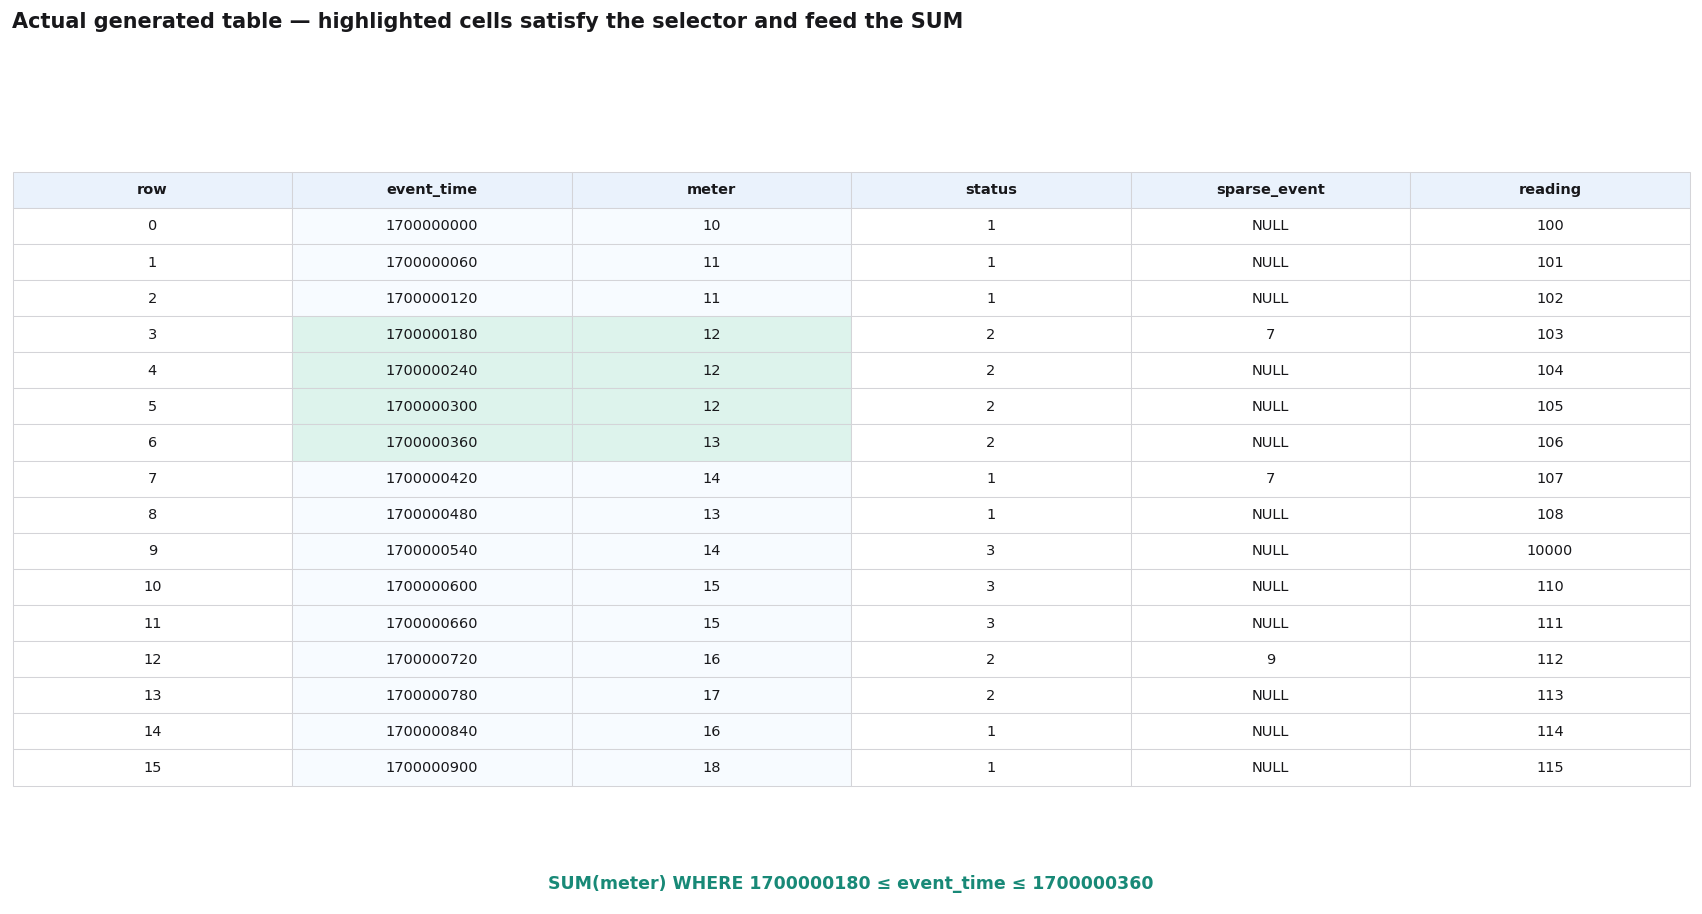

In [4]:
example = read_csv(GENERATED / "example_values.csv")
columns = list(example[0])
matrix = [[row[c] if row[c] else "NULL" for c in columns] for row in example]
low, high = 1_700_000_180, 1_700_000_360

fig, ax = plt.subplots(figsize=(13.5, 7.2), constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
table = ax.table(cellText=matrix, colLabels=columns, cellLoc="center", loc="center")
table.auto_set_font_size(False); table.set_fontsize(8.4); table.scale(1, 1.42)
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor(GRID); cell.set_linewidth(0.6)
    if r == 0:
        cell.set_facecolor("#EAF2FC"); cell.set_text_props(weight="bold", color=INK)
    elif 4 <= r <= 7 and c in (1, 2):
        cell.set_facecolor("#DDF3EC")
    elif c in (1, 2):
        cell.set_facecolor("#F7FBFF")
ax.set_title(
    "Actual generated table — highlighted cells satisfy the selector and feed the SUM",
    loc="left", pad=16, weight="bold",
)
ax.text(0.5, 0.015,
        f"SUM(meter) WHERE {low} ≤ event_time ≤ {high}",
        transform=ax.transAxes, ha="center", color=TEAL, weight="bold")
plt.show()


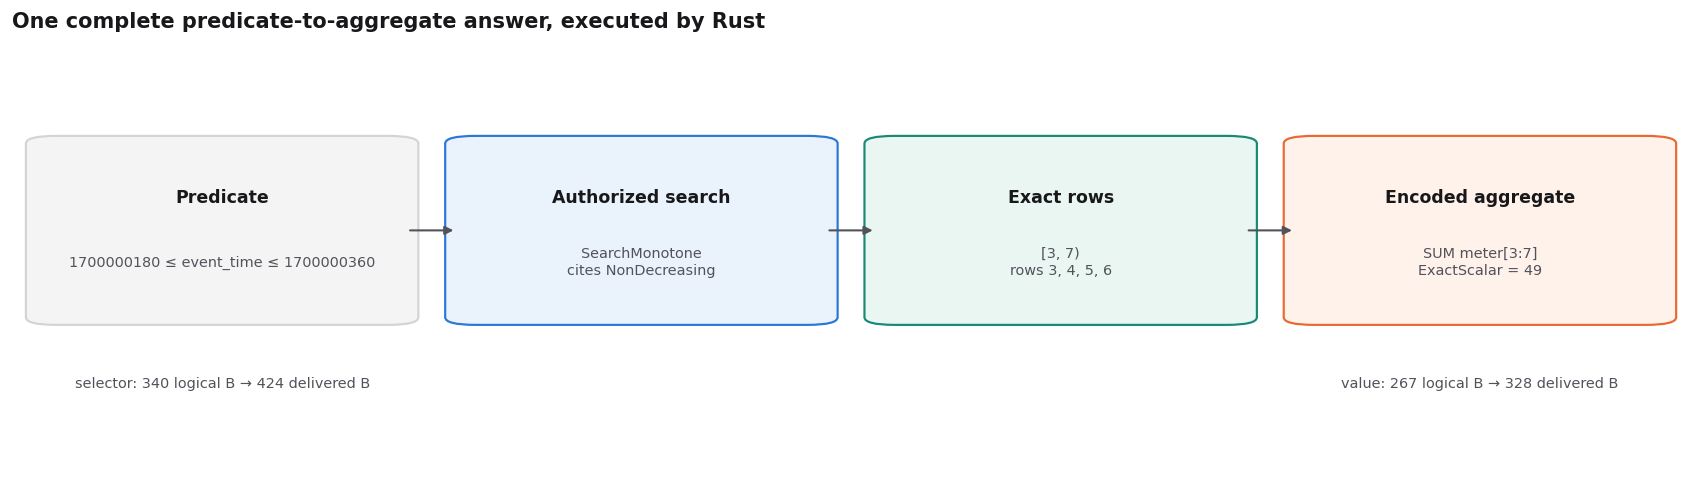

Independent check: selected rows and SUM agree with the generated logical table.


In [5]:
# Execute both legs through the current Rust runtime, then independently check the answer.
event_time = [int(r["event_time"]) for r in example]
meter = [int(r["meter"]) for r in example]
predicate = {"kind": "filter_between", "low": low, "high": high}

selector_run = witness("run", values=event_time,
                       recipe="UnsignedDelta(128, BitPack)", query=predicate)
ranges = selector_run["answer"]["ranges"]
assert ranges == [[3, 7]]
value_run = witness("run", values=meter, recipe="For(BitPack)",
                    query={"kind": "sum", "start": 3, "end": 7})
assert value_run["answer"]["value"] == sum(meter[3:7]) == 49

fig, ax = plt.subplots(figsize=(13.5, 3.7), constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
stages = [
    ("Predicate", f"{low} ≤ event_time ≤ {high}", "#F4F4F5", GRID),
    ("Authorized search", "SearchMonotone\ncites NonDecreasing", "#EAF2FC", BLUE),
    ("Exact rows", "[3, 7)\nrows 3, 4, 5, 6", "#E9F6F2", TEAL),
    ("Encoded aggregate", "SUM meter[3:7]\nExactScalar = 49", "#FFF2EA", ORANGE),
]
for i, (title, body, face, edge) in enumerate(stages):
    x = 0.02 + i * 0.25
    box(ax, (x, 0.34), 0.21, 0.42, title, body, face, edge)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 0.245, 0.55), xytext=(x + 0.215, 0.55),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
ax.text(0.125, 0.18,
        f"selector: {selector_run['logical_bytes']} logical B → {selector_run['delivered_bytes']} delivered B",
        ha="center", fontsize=8.3, color=MUTED)
ax.text(0.875, 0.18,
        f"value: {value_run['logical_bytes']} logical B → {value_run['delivered_bytes']} delivered B",
        ha="center", fontsize=8.3, color=MUTED)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("One complete predicate-to-aggregate answer, executed by Rust", loc="left", weight="bold")
plt.show()
print("Independent check: selected rows and SUM agree with the generated logical table.")


**Reading the trace**

- `SearchMonotone` returns an exact row interval; it is not a heuristic candidate.
- `AggregateEncoded` runs only on `[3,7)`, and the Rust result is independently
  checked against the visible table.
- Logical bytes name requested fields. Delivered bytes include the alignment and
  field granularity the physical page forces the reader to fetch.
- This example establishes semantics and accounting, not a latency speedup.


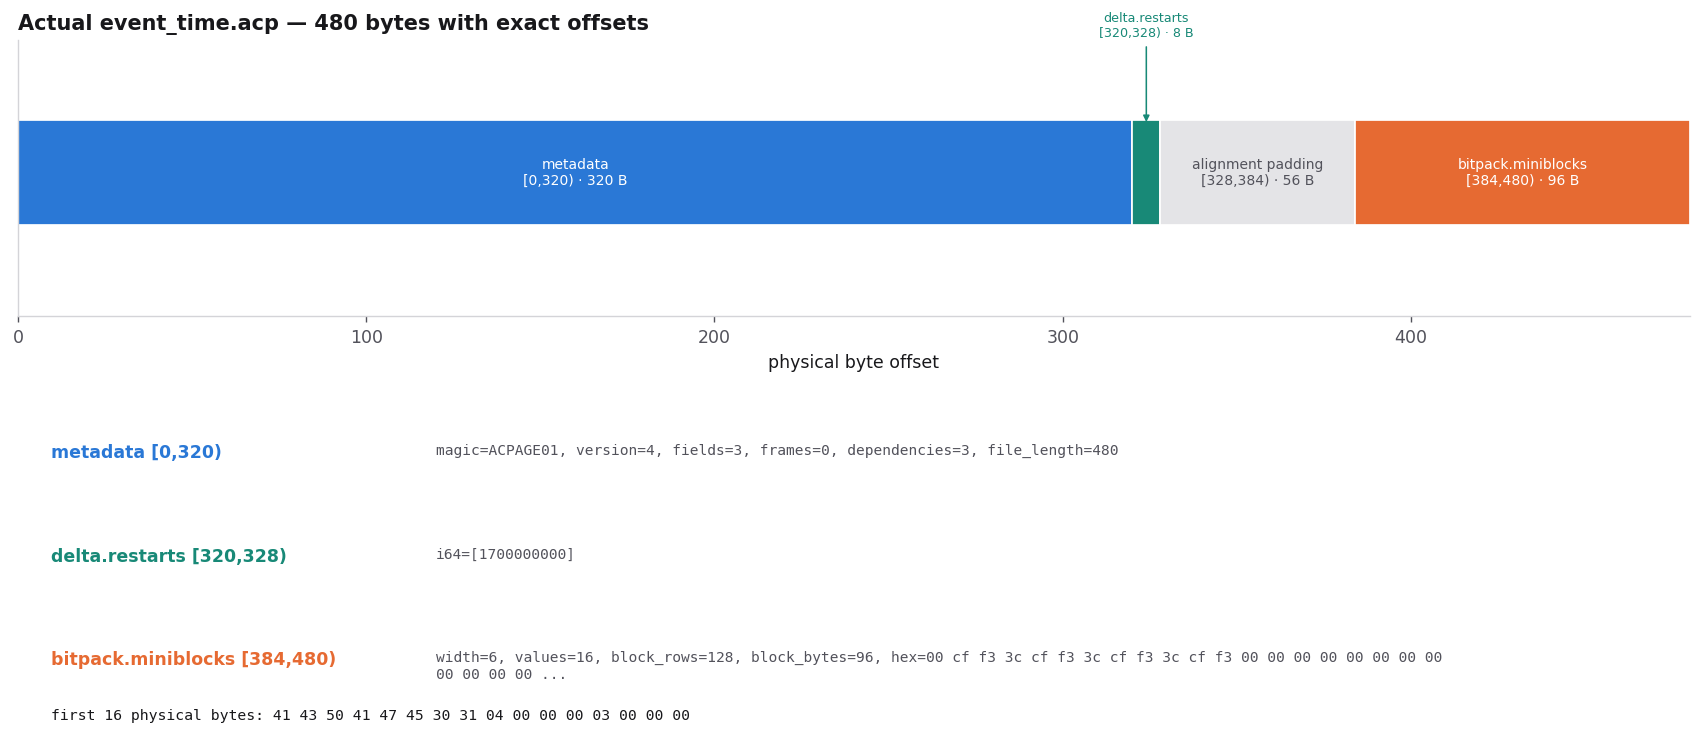

In [6]:
# Exact byte map for the selector page, loaded from the Rust-generated layout CSV.
layout = read_csv(GENERATED / "witness_layout.csv")
event_layout = [r for r in layout if r["column"] == "event_time"]
page_bytes = int(event_layout[0]["page_bytes"])

def physical_span(row):
    match = re.match(r"\[(\d+),(\d+)\)", row["location"])
    return tuple(map(int, match.groups()))

fields = [(r["field"], *physical_span(r), r["content"]) for r in event_layout]
segments, cursor = [], 0
for name, start, end, content in sorted(fields, key=lambda x: x[1]):
    if cursor < start:
        segments.append(("alignment padding", cursor, start, ""))
    segments.append((name, start, end, content)); cursor = end

colours = {"metadata": BLUE, "delta.restarts": TEAL,
           "bitpack.miniblocks": ORANGE, "alignment padding": "#E4E4E7"}
fig, (ax, detail) = plt.subplots(2, 1, figsize=(13.5, 5.8),
                                gridspec_kw={"height_ratios": [1, 1.25]},
                                constrained_layout=True)
for axis in (ax, detail):
    axis.grid(False)
ax.set_ylim(0, 1); ax.set_yticks([]); ax.set_xlim(0, page_bytes)
for name, start, end, _ in segments:
    ax.barh(0.52, end - start, left=start, height=0.38,
            color=colours[name], edgecolor="white")
    label = f"{name}\n[{start},{end}) · {end-start} B"
    if end - start >= 45:
        ax.text((start + end) / 2, 0.52, label, ha="center", va="center",
                fontsize=8, color="white" if name != "alignment padding" else MUTED)
    else:
        ax.annotate(label, xy=((start + end) / 2, 0.69), xytext=((start + end) / 2, 1.00),
                    ha="center", va="bottom", fontsize=7.3, color=colours[name],
                    arrowprops=dict(arrowstyle="-|>", color=colours[name], lw=0.9))
ax.set_xlabel("physical byte offset")
ax.set_title(f"Actual event_time.acp — {page_bytes} bytes with exact offsets", loc="left", weight="bold")

detail.set_axis_off()
for i, (name, start, end, content) in enumerate(fields):
    y = 0.82 - i * 0.30
    detail.text(0.02, y, f"{name} [{start},{end})", transform=detail.transAxes,
                weight="bold", color=colours[name], va="top")
    detail.text(0.25, y, textwrap.fill(content, 115), transform=detail.transAxes,
                fontsize=8.4, color=MUTED, va="top", family="monospace")
magic = (GENERATED / "artifacts/event_time.acp").read_bytes()[:16].hex(" ")
detail.text(0.02, 0.02, f"first 16 physical bytes: {magic}", transform=detail.transAxes,
            family="monospace", fontsize=8.5, color=INK)
plt.show()


**Physical interpretation**

- The first 320 bytes are the authenticated page descriptor and field directory.
- The 8-byte restart anchor begins at byte 320. Its label is outside the narrow
  segment so its true width remains visible.
- Bytes `[328,384)` are alignment padding, not hidden payload.
- The bit-packed miniblock records its width, row count, block size, and real byte
  prefix; these values come from the generated layout CSV and `.acp` file.


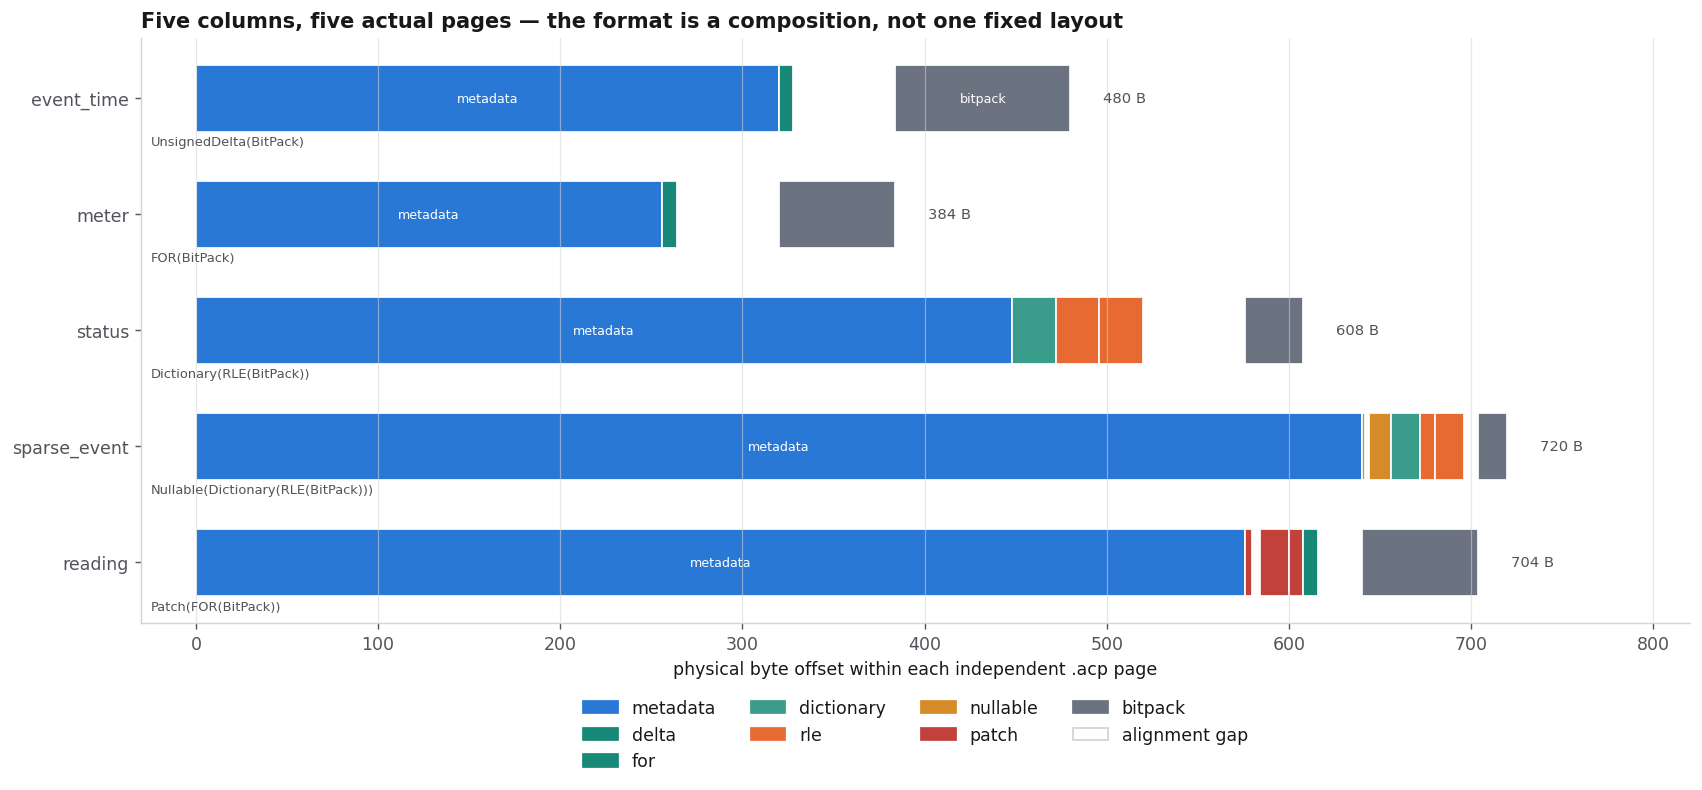

In [7]:
# All five real Witness pages: nesting changes fields, dependencies, and header size.
field_colour = {
    "metadata": BLUE, "delta": TEAL, "for": TEAL, "dictionary": "#3A9D8B",
    "rle": ORANGE, "nullable": "#D58B27", "patch": RED, "bitpack": "#6B7280",
}
def family(name):
    return next((k for k in field_colour if name.startswith(k)), "bitpack")

order = ["event_time", "meter", "status", "sparse_event", "reading"]
fig, ax = plt.subplots(figsize=(13.5, 6.2), constrained_layout=True)
for y, column in enumerate(order[::-1]):
    rows = [r for r in layout if r["column"] == column]
    total = int(rows[0]["page_bytes"])
    for row in rows:
        start, end = physical_span(row)
        colour = field_colour[family(row["field"])]
        ax.barh(y, end-start, left=start, height=0.58, color=colour, edgecolor="white")
        if end-start >= 70:
            ax.text((start+end)/2, y, row["field"].replace(".miniblocks", ""),
                    ha="center", va="center", fontsize=7.3, color="white")
    ax.text(total + 18, y, f"{total} B", va="center", fontsize=8.5, color=MUTED)
    recipe = rows[0]["recipe"]
    ax.text(-25, y-0.33, recipe, va="top", fontsize=7.5, color=MUTED)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order[::-1])
ax.set_xlabel("physical byte offset within each independent .acp page")
ax.set_title("Five columns, five actual pages — the format is a composition, not one fixed layout",
             loc="left", weight="bold")
ax.set_xlim(-30, max(int(r["page_bytes"]) for r in layout) + 100)
handles = [mpl.patches.Patch(color=v, label=k) for k, v in field_colour.items()]
handles.append(mpl.patches.Patch(color="white", ec=GRID, label="alignment gap"))
ax.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28))
ax.grid(axis="y", visible=False)
plt.show()


**Why the five layouts differ**

- `event_time` needs an anchor and packed deltas; `meter` needs a FOR base.
- `status` adds dictionary and run metadata; `sparse_event` adds validity and rank
  fields; `reading` isolates one exception with patch metadata.
- White gaps are physical alignment. They count toward page bytes even though they
  carry no logical values.
- Each column is currently an independent page. Witness does not claim a production
  multi-column table container.


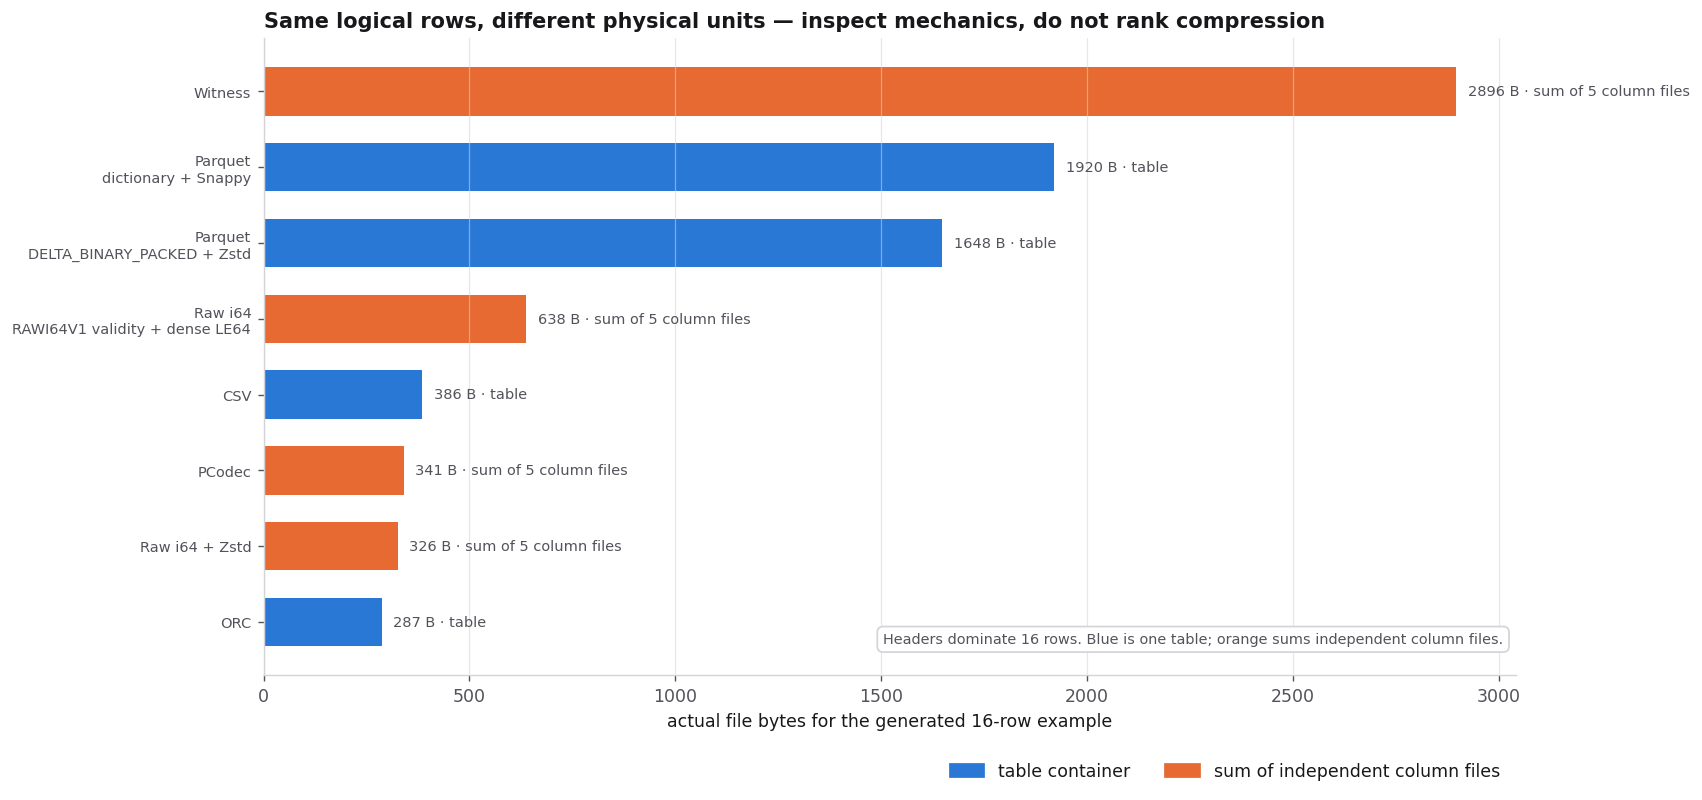

In [8]:
# Real small files generated from the same 16 rows. This is a mechanics view, not a ratio result.
formats = read_csv(GENERATED / "format_artifacts.csv")
formats = sorted(formats, key=lambda r: int(r["bytes"]))
names = [r["format"] + ("\n" + r["configuration"] if r["format"] in {"Parquet", "Raw i64"} else "")
         for r in formats]
sizes = [int(r["bytes"]) for r in formats]
is_table = ["one 5-column table" in r["physical_unit"] for r in formats]
colours = [BLUE if table else ORANGE for table in is_table]

fig, ax = plt.subplots(figsize=(13.5, 6.3), constrained_layout=True)
bars = ax.barh(range(len(formats)), sizes, color=colours, height=0.64)
for bar, row in zip(bars, formats):
    unit = "table" if "one 5-column table" in row["physical_unit"] else "sum of 5 column files"
    ax.text(bar.get_width() + 28, bar.get_y() + bar.get_height()/2,
            f"{row['bytes']} B · {unit}", va="center", fontsize=8.4, color=MUTED)
ax.set_yticks(range(len(formats))); ax.set_yticklabels(names, fontsize=8.4)
ax.set_xlabel("actual file bytes for the generated 16-row example")
ax.set_title("Same logical rows, different physical units — inspect mechanics, do not rank compression",
             loc="left", weight="bold")
ax.text(0.99, 0.05,
        "Headers dominate 16 rows. Blue is one table; orange sums independent column files.",
        transform=ax.transAxes, ha="right", fontsize=8.3, color=MUTED,
        bbox=dict(facecolor="white", edgecolor=GRID, boxstyle="round,pad=0.4"))
ax.legend(handles=[mpl.patches.Patch(color=BLUE, label="table container"),
                   mpl.patches.Patch(color=ORANGE, label="sum of independent column files")],
          loc="lower right", bbox_to_anchor=(1, -0.19), ncol=2)
ax.grid(axis="y", visible=False)
plt.show()

assert all(r["performance_claim"] == "false" for r in formats)


**How to read the format plot**

- Every bar is a real generated file and is round-trip checked by the Rust
  documentation study.
- Blue bars are one five-column table; orange bars sum five self-contained column
  files. Their fixed metadata is therefore not directly comparable.
- Sixteen rows are intentionally header dominated. The plot explains physical
  packaging and file identity; it makes no compression or speed claim.


## 2. From bytes to permission

The page map answers **where** data lives. It does not yet answer **which
algorithm is sound**. The contract keeps two axes independent:

- a **value fact** such as `NonDecreasing`, with evidence explaining why it is
  trusted;
- an **access capability** describing whether the fields needed for a probe are
  locally deliverable or trapped inside an enclosing frame.

Only their combination determines the useful plan. An enclosing frame may retain
the fact while making every selective request deliver the whole frame; direct
restart data may be locally reachable while proving no row order.

The separation is represented directly by
[`decoder.rs`](../../src/access_compiler/decoder.rs),
[`layout.rs`](../../src/access_compiler/layout.rs),
[`invariants.rs`](../../src/access_compiler/invariants.rs), and
[`format.rs`](../../src/access_compiler/format.rs).


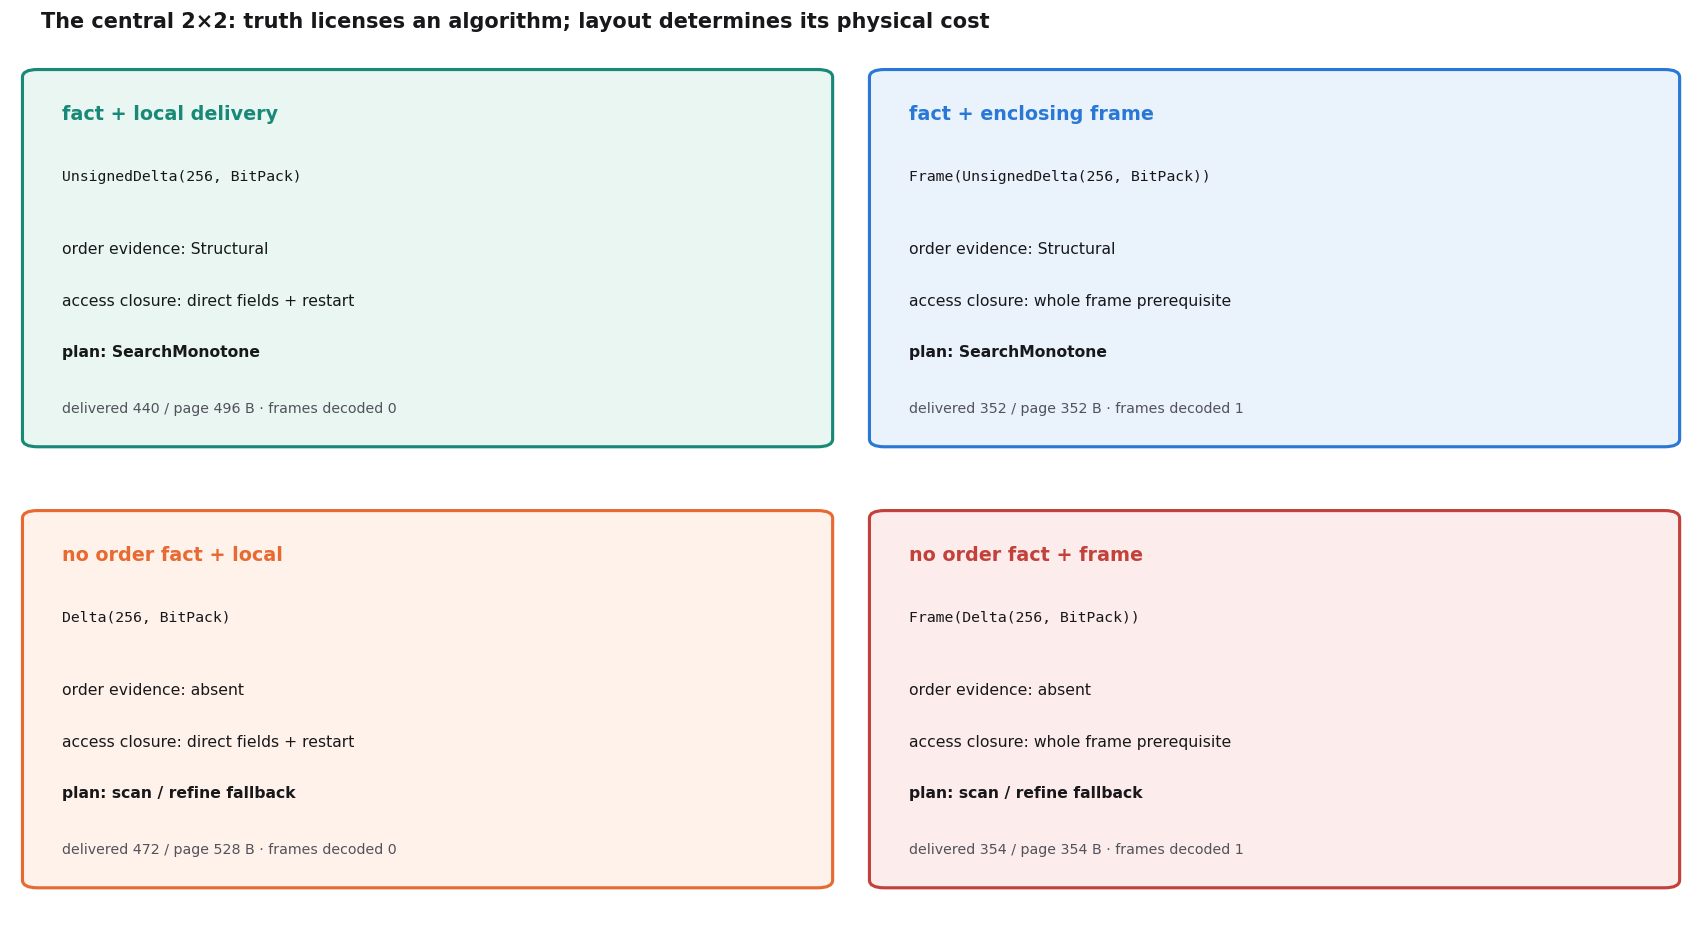

In [9]:
ordered = [1000,1003,1004,1004,1007,1012,1012,1015,1101,1101,1104,1110]
unordered = [1000,1003,900,1004,1007,1012,880,1015,1101,1101,1104,1110]
cases = [
    ("fact + local delivery", ordered, "UnsignedDelta(256, BitPack)"),
    ("fact + enclosing frame", ordered, "Frame(UnsignedDelta(256, BitPack))"),
    ("no order fact + local", unordered, "Delta(256, BitPack)"),
    ("no order fact + frame", unordered, "Frame(Delta(256, BitPack))"),
]
observed = []
for label, values, recipe in cases:
    facts = witness("facts", values=values, recipe=recipe)["facts"]
    plan = witness("compile", values=values, recipe=recipe,
                   query={"kind":"filter_between", "low":1004, "high":1015})
    run = witness("run", values=values, recipe=recipe,
                  query={"kind":"filter_between", "low":1004, "high":1015})
    order = next((f["evidence"] for f in facts if "NonDecreasing" in f["property"]), None)
    enclosing = next((f for f in facts if "EnclosingFrame" in f["property"]), None)
    fast = any("SearchMonotone" in n["op"] for n in plan["nodes"])
    observed.append((label, recipe, order, enclosing is not None, fast, run))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 7.3), constrained_layout=True)
for ax, (label, recipe, order, framed, fast, run) in zip(axes.flat, observed):
    ax.set_axis_off(); ax.grid(False)
    face = "#E9F6F2" if fast and not framed else "#EAF2FC" if fast else "#FFF2EA" if not framed else "#FCECEB"
    edge = TEAL if fast and not framed else BLUE if fast else ORANGE if not framed else RED
    ax.add_patch(mpl.patches.FancyBboxPatch((0.03,0.08),0.94,0.84,
                 boxstyle="round,pad=0.018", facecolor=face, edgecolor=edge, linewidth=1.8))
    ax.text(0.06,0.82,label,transform=ax.transAxes,weight="bold",color=edge,fontsize=11)
    ax.text(0.06,0.68,textwrap.fill(recipe, 40),transform=ax.transAxes,family="monospace",fontsize=8.5)
    ax.text(0.06,0.51,
            "order evidence: " + (order.split("(")[0] if order else "absent"),
            transform=ax.transAxes,fontsize=9)
    ax.text(0.06,0.39,
            "access closure: " + ("whole frame prerequisite" if framed else "direct fields + restart"),
            transform=ax.transAxes,fontsize=9)
    ax.text(0.06,0.27,
            "plan: " + ("SearchMonotone" if fast else "scan / refine fallback"),
            transform=ax.transAxes,fontsize=9,weight="bold")
    ax.text(0.06,0.14,
            f"delivered {run['delivered_bytes']} / page {run['page_bytes']} B · frames decoded {run['frames_decoded']}",
            transform=ax.transAxes,fontsize=8.2,color=MUTED)
fig.suptitle("The central 2×2: truth licenses an algorithm; layout determines its physical cost",
             x=0.02, ha="left", weight="bold")
plt.show()


**Why the 2×2 is the core result**

- The upper row has an order fact, so both direct and framed pages may use
  `SearchMonotone`.
- The right column has an enclosing-frame prerequisite. The algorithm remains
  sound, but a selective request delivers and decodes the complete frame.
- The lower row has restart access but no order fact, so the compiler records a
  scan/refinement fallback.
- A frame can still be smaller in absolute bytes. “Not selectively accessible”
  does not mean “always slower.”


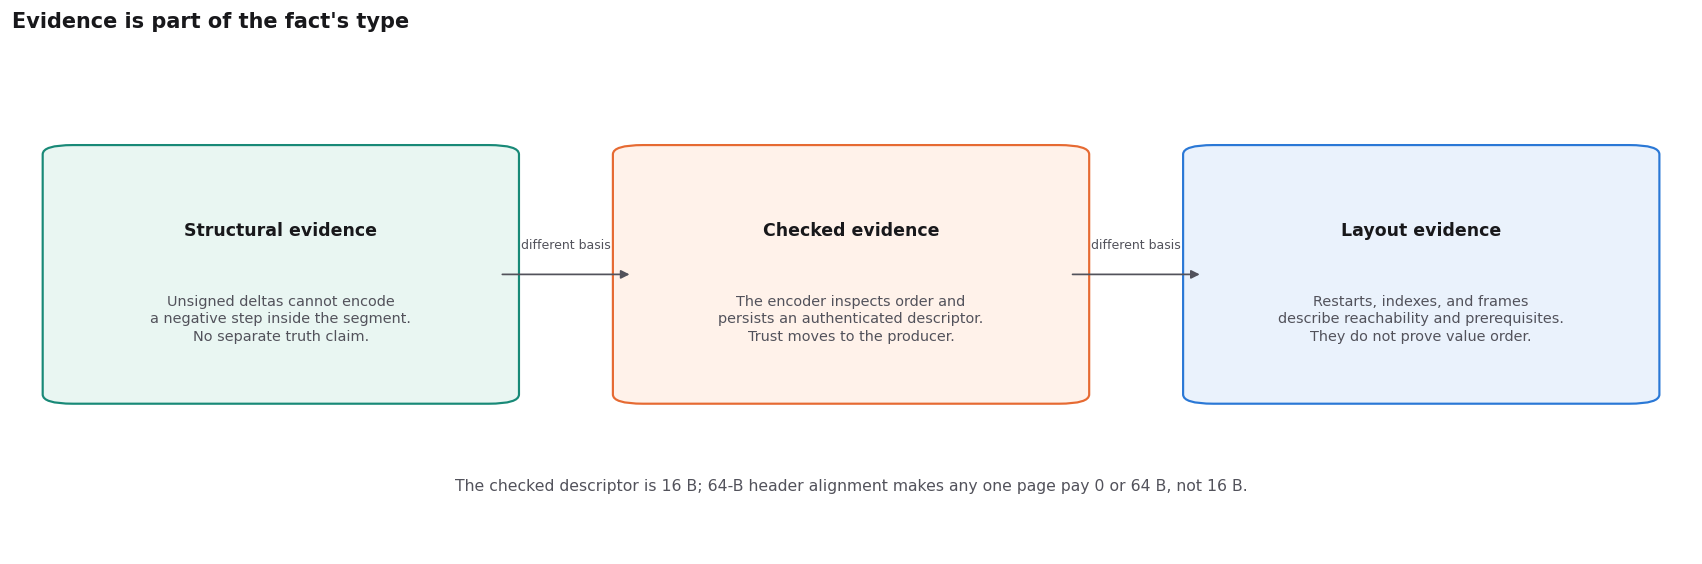

UnsignedDelta(256, BitPack)        -> Structural("unsigned_delta_segments"), CheckedDescriptor("non_decreasing")
Delta(256, BitPack)                -> CheckedDescriptor("non_decreasing")


In [10]:
# Same true property, different evidence and trust boundary.
evidence_rows = []
for recipe in ["UnsignedDelta(256, BitPack)", "Delta(256, BitPack)"]:
    facts = witness("facts", values=ordered, recipe=recipe)["facts"]
    evidence = [f["evidence"] for f in facts if f["property"] == "Value(NonDecreasing)"]
    evidence_rows.append((recipe, evidence))

fig, ax = plt.subplots(figsize=(13.5, 4.4), constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
box(ax, (0.03,0.30), 0.26,0.48, "Structural evidence",
    "Unsigned deltas cannot encode\na negative step inside the segment.\nNo separate truth claim.", "#E9F6F2", TEAL)
box(ax, (0.37,0.30), 0.26,0.48, "Checked evidence",
    "The encoder inspects order and\npersists an authenticated descriptor.\nTrust moves to the producer.", "#FFF2EA", ORANGE)
box(ax, (0.71,0.30), 0.26,0.48, "Layout evidence",
    "Restarts, indexes, and frames\ndescribe reachability and prerequisites.\nThey do not prove value order.", "#EAF2FC", BLUE)
for x1, x2 in [(0.29,0.37),(0.63,0.71)]:
    ax.annotate("", xy=(x2,0.54), xytext=(x1,0.54),
                arrowprops=dict(arrowstyle="-|>", color=MUTED))
    ax.text((x1+x2)/2,0.59,"different basis",ha="center",fontsize=7.2,color=MUTED)
ax.text(0.5,0.12,
        f"The checked descriptor is {claim('WitCertificateHeaderBytes')} B; 64-B header alignment makes any one page pay 0 or 64 B, not 16 B.",
        ha="center", fontsize=9, color=MUTED)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("Evidence is part of the fact's type", loc="left", weight="bold")
plt.show()

for recipe, evidence in evidence_rows:
    print(f"{recipe:34s} -> {', '.join(evidence)}")


**Trust and storage cost**

- Structural evidence follows from what the encoding can represent; a separate
  truth flag cannot become stale because none is needed.
- Checked evidence can certify the same property for signed encodings, but the
  reader trusts the producer's check and authenticated descriptor.
- The descriptor adds 16 logical bytes. Header alignment quantizes the realized
  cost of any one page to 0 or 64 bytes; the final regression test checks this
  against committed pages.


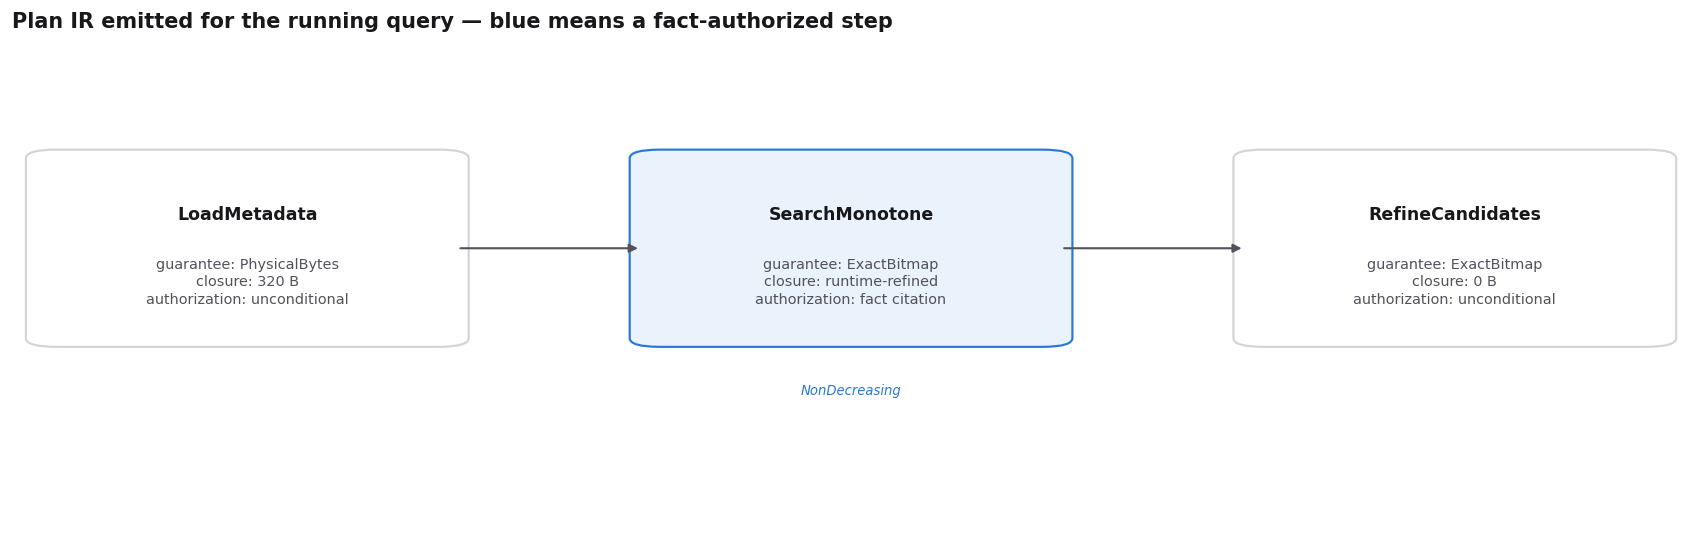

In [11]:
# The actual compiler plan: every non-scan step carries its authorization and closure.
plan = witness("compile", values=event_time, recipe="UnsignedDelta(128, BitPack)",
               query={"kind":"filter_between", "low":low, "high":high})
nodes = plan["nodes"]
fig, ax = plt.subplots(figsize=(13.5, 4.2), constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
xs = np.linspace(0.14, 0.86, len(nodes))
for x, node in zip(xs, nodes):
    cited = node["cites"] != "unconditional"
    op = node["op"].split(" {")[0]
    closure = f"{node['closure_bytes']} B" if node["closure"] == "exact" else "runtime-refined"
    box(ax, (x-0.12,0.38),0.24,0.38,op,
        f"guarantee: {node['guarantee'].split('(')[0]}\nclosure: {closure}\n"
        f"authorization: {'fact citation' if cited else 'unconditional'}",
        "#EAF2FC" if cited else "white", BLUE if cited else GRID)
    if cited:
        ax.text(x,0.27,node["cites"].replace("AllRows::Value(","").rstrip(")"),
                ha="center",fontsize=7.6,color=BLUE,style="italic")
for x1,x2 in zip(xs,xs[1:]):
    ax.annotate("",xy=(x2-0.125,0.57),xytext=(x1+0.125,0.57),
                arrowprops=dict(arrowstyle="-|>",color=MUTED,lw=1.2))
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("Plan IR emitted for the running query — blue means a fact-authorized step",
             loc="left",weight="bold")
plt.show()


**Plan semantics**

- `LoadMetadata` and final refinement are unconditional correctness steps.
- `SearchMonotone` is the only fact-authorized node in this plan. Its citation is
  rechecked before execution.
- `RuntimeRefined` means later byte spans depend on search probes; it is an explicit
  envelope, not an estimated static byte count.
- Output guarantees prevent a candidate bitmap from being returned as an exact
  answer.


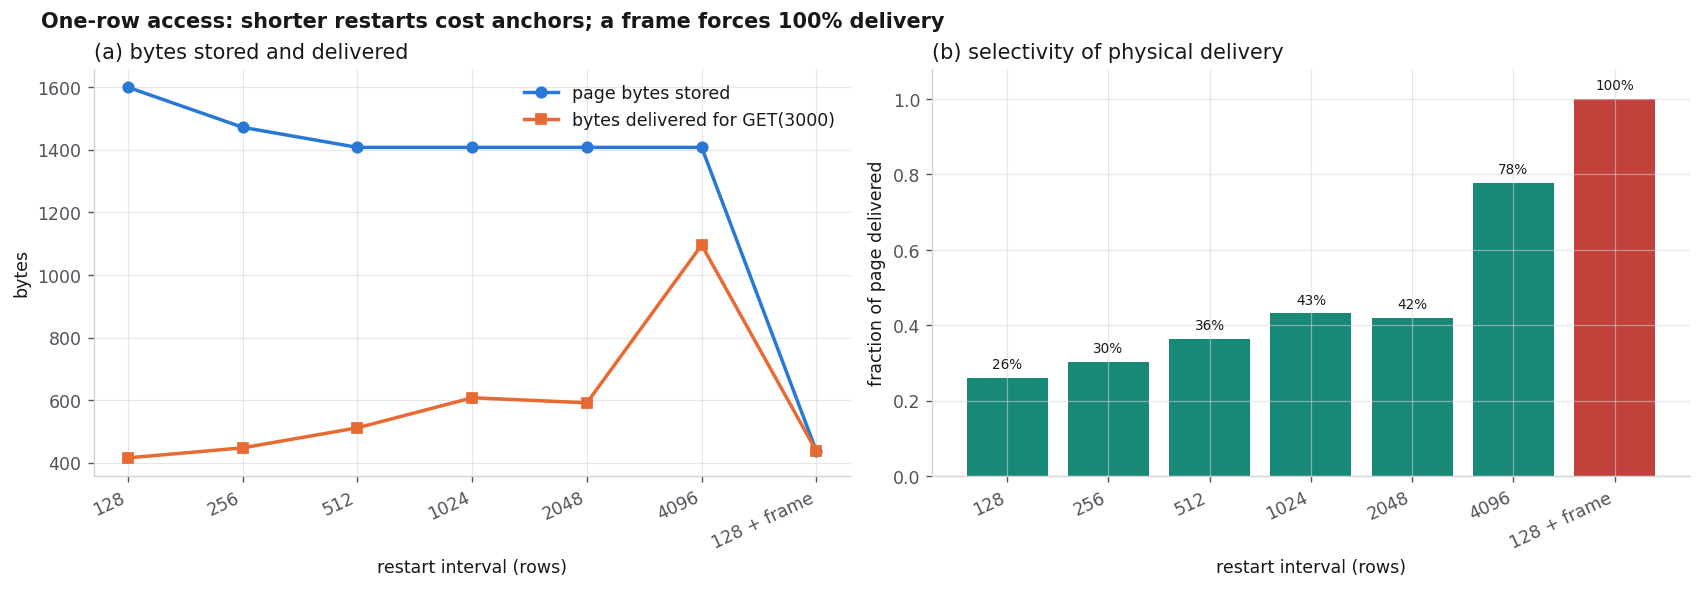

In [12]:
# Restart spacing and framing expose the storage/access trade on a single point lookup.
run_values = list(range(0, 8192, 2))
specs = [(str(r), f"UnsignedDelta({r}, BitPack)") for r in (128,256,512,1024,2048,4096)]
specs.append(("128 + frame", "Frame(UnsignedDelta(128, BitPack))"))
measure = []
for label, recipe in specs:
    got = witness("run", values=run_values, recipe=recipe, query={"kind":"get", "row":3000})
    measure.append((label, got["page_bytes"], got["delivered_bytes"], got["frames_decoded"]))

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(13.5,4.6),constrained_layout=True)
labels = [m[0] for m in measure]; page = np.array([m[1] for m in measure]); delivered = np.array([m[2] for m in measure])
x = np.arange(len(labels))
ax1.plot(x,page,marker="o",color=BLUE,lw=2,label="page bytes stored")
ax1.plot(x,delivered,marker="s",color=ORANGE,lw=2,label="bytes delivered for GET(3000)")
ax1.set_xticks(x); ax1.set_xticklabels(labels,rotation=25,ha="right")
ax1.set_ylabel("bytes"); ax1.set_xlabel("restart interval (rows)")
ax1.set_title("(a) bytes stored and delivered",loc="left"); ax1.legend()
fractions = delivered/page
bars=ax2.bar(x,fractions,color=[TEAL]*6+[RED])
ax2.set_xticks(x); ax2.set_xticklabels(labels,rotation=25,ha="right")
ax2.set_ylim(0,1.08); ax2.set_ylabel("fraction of page delivered")
ax2.set_xlabel("restart interval (rows)")
ax2.set_title("(b) selectivity of physical delivery",loc="left")
for b,v in zip(bars,fractions):
    ax2.text(b.get_x()+b.get_width()/2,v+0.025,f"{v:.0%}",ha="center",fontsize=7.8)
fig.suptitle("One-row access: shorter restarts cost anchors; a frame forces 100% delivery",
             x=0.02,ha="left",weight="bold")
plt.show()


**The restart trade**

- Short intervals store more anchors but bound how many deltas a point lookup must
  reconstruct.
- Long intervals shrink the restart directory while increasing the lookup closure.
- The enclosing frame is compact here, yet the one-row lookup delivers 100% of it.
- The study's two policies choose different points on this same storage/access
  frontier; neither point dominates for every workload.


## 3. How the study tests the mechanism

The single-page evaluation is deliberately split into three questions:

- **Q1 — availability:** how often does a real representation provide a useful
  fact, and is that fact physically usable?
- **Q2 — effect:** which part of the query disappears when the fact authorizes a
  different algorithm?
- **Q3 — price:** how many stored bytes preserve the access path needed to spend
  that fact?

The external format is a calibration point. The causal comparison is internal:
the same values, query, compiler, and codec menu are encoded once for minimum size
and once for bounded local access. Every timed arm must first return identical rows
and sums.

Corpus loading and query construction live in
[`datasets.rs`](../../src/experiment/datasets.rs) and
[`time_window.rs`](../../src/experiment/time_window.rs). The claim-bearing run is
orchestrated by [`predicate_pipeline_study.rs`](../../src/bin/predicate_pipeline_study.rs),
and [`claim_manifest.rs`](../../src/bin/claim_manifest.rs) turns canonical CSV cells
into the displayed values.


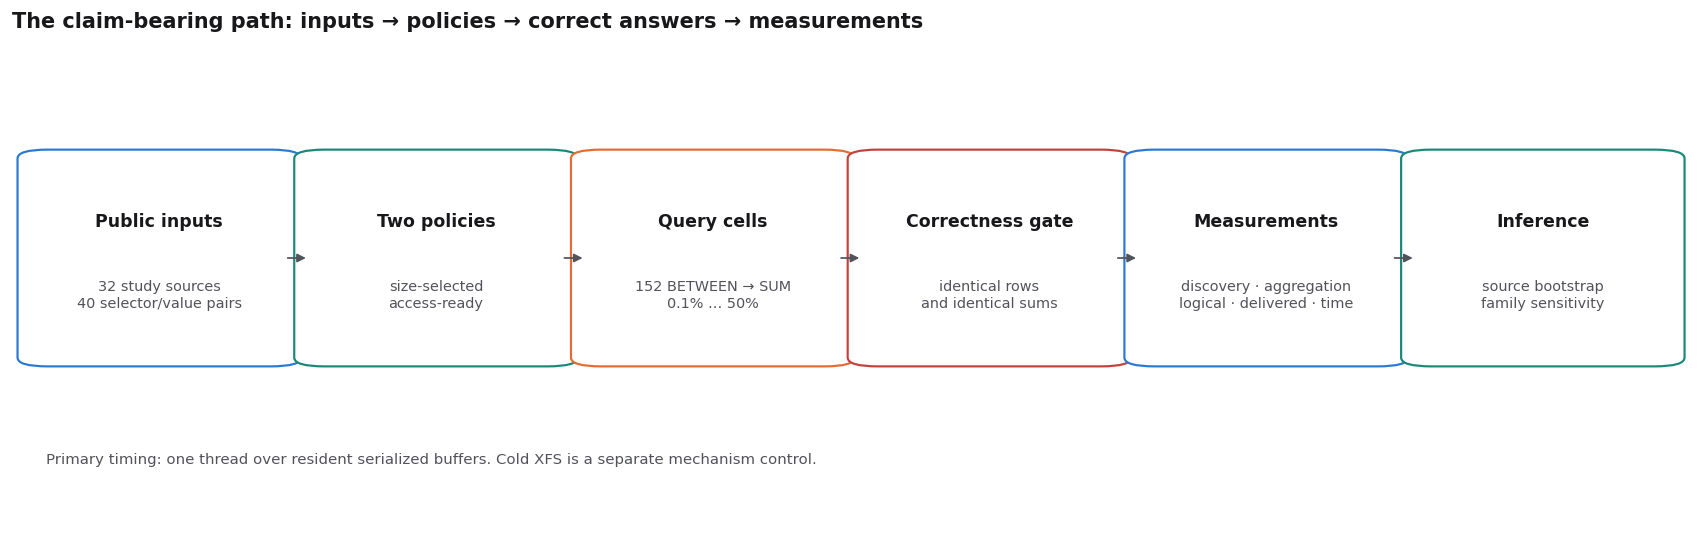

Measurement environment
  rustc 1.96.0 (ac68faa20 2026-05-25)
  Linux e1-g0001 6.8.0-88-generic #89-Ubuntu SMP PREEMPT_DYNAMIC Sat Oct 11 01:02:46 UTC 2025 x86_64 x86_64 x86_64 GNU/Linux
  CPU(s):                               64
  Model name:                           AMD EPYC 9124 16-Core Processor
  L3 cache:                             128 MiB (8 instances)
  /data  /dev/sda xfs    rw,relatime,attr2,inode64,logbufs=8,logbsize=32k,sunit=128,swidth=640,noquota


In [13]:
stages = [
    ("Public inputs", f"{claim('WitSources')} study sources\n{claim('WitPairs')} selector/value pairs", BLUE),
    ("Two policies", "size-selected\naccess-ready", TEAL),
    ("Query cells", f"{claim('WitCells')} BETWEEN → SUM\n0.1% … 50%", ORANGE),
    ("Correctness gate", "identical rows\nand identical sums", RED),
    ("Measurements", "discovery · aggregation\nlogical · delivered · time", BLUE),
    ("Inference", "source bootstrap\nfamily sensitivity", TEAL),
]
fig, ax = plt.subplots(figsize=(13.5,4.2),constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
for i,(title,body,colour) in enumerate(stages):
    x=0.015+i*0.165
    box(ax,(x,0.34),0.145,0.42,title,body,"white",colour)
    if i<len(stages)-1:
        ax.annotate("",xy=(x+0.162,0.55),xytext=(x+0.147,0.55),
                    arrowprops=dict(arrowstyle="-|>",color=MUTED,lw=1.0))
ax.text(0.02,0.13,
        "Primary timing: one thread over resident serialized buffers. Cold XFS is a separate mechanism control.",
        fontsize=8.6,color=MUTED)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("The claim-bearing path: inputs → policies → correct answers → measurements",
             loc="left",weight="bold")
plt.show()

env = (RESULTS / "predicate_pipeline/environment.txt").read_text().splitlines()
keys = [line for line in env if line.startswith(("rustc ","Linux ","CPU(s):","Model name:","L3 cache:","/data "))]
print("Measurement environment")
for line in keys:
    print("  " + line)


**Evaluation contract**

- Encoding policies are outcome-blind: they are selected before query latency is
  known.
- Every timed arm must produce identical row positions and sums.
- The primary ratios use resident serialized buffers and one thread; cold XFS is a
  separate mechanism experiment.
- Repetitions characterize timing precision. Bootstrap intervals resample sources,
  with archive-family sensitivity reported separately.


## 4. Results: availability, effect, and price

The following figures are not copied images. They are regenerated here from the
same canonical CSVs and claim manifest the study publishes. The
captions separate mechanism evidence from population claims and physical byte
accounting from device behavior.

The census is produced by
[`invariant_census_study.rs`](../../src/bin/invariant_census_study.rs); predicate
timings and byte accounting come from the generated-kernel pipeline and
[`runtime.rs`](../../src/access_compiler/runtime.rs).


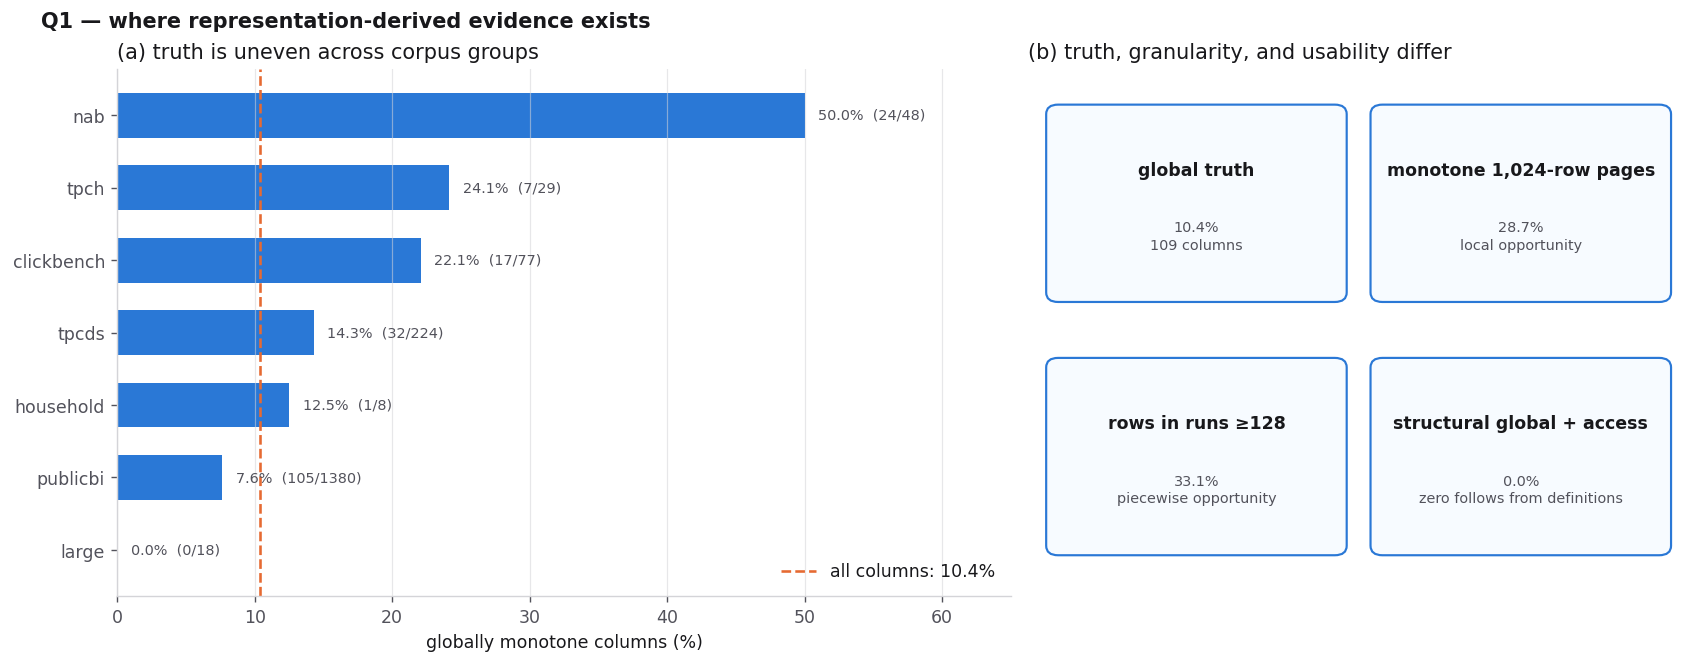

In [14]:
# Q1: incidence varies by corpus; one global percentage hides the mechanism's domain.
sources = read_csv(RESULTS / "invariant_census/sources.csv")
groups = {}
for row in sources:
    group = groups.setdefault(row["group"], [0,0])
    group[0] += int(row["columns"]); group[1] += int(row["global_monotone_columns"])
names = sorted(groups, key=lambda g: groups[g][1]/groups[g][0])
shares = [100*groups[g][1]/groups[g][0] for g in names]

fig, (ax, cards) = plt.subplots(1,2,figsize=(13.5,5.2),
                                gridspec_kw={"width_ratios":[1.35,1]},constrained_layout=True)
bars=ax.barh(names,shares,color=BLUE,height=0.62)
for bar,name,pct in zip(bars,names,shares):
    n=groups[name][0]
    ax.text(pct+1,bar.get_y()+bar.get_height()/2,f"{pct:.1f}%  ({groups[name][1]}/{n})",
            va="center",fontsize=8.3,color=MUTED)
ax.axvline(float(claim("WitCensusMonotoneColumns")),color=ORANGE,ls="--",lw=1.5,
           label=f"all columns: {claim('WitCensusMonotoneColumns')}%")
ax.set_xlim(0,max(shares)+15); ax.set_xlabel("globally monotone columns (%)")
ax.set_title("(a) truth is uneven across corpus groups",loc="left"); ax.legend(loc="lower right")
ax.grid(axis="y",visible=False)

cards.set_axis_off(); cards.grid(False)
card_data=[
    ("global truth",f"{claim('WitCensusMonotoneColumns')}%","109 columns"),
    ("monotone 1,024-row pages",f"{claim('WitCensusMonotonePages')}%","local opportunity"),
    ("rows in runs ≥128",f"{claim('WitCensusSegmentFraction')}%","piecewise opportunity"),
    ("structural global + access",f"{claim('WitCensusStructuralAccessReady')}%","zero follows from definitions"),
]
for i,(title,value,note) in enumerate(card_data):
    x=0.04+(i%2)*0.49; y=0.57-(i//2)*0.48
    box(cards,(x,y),0.43,0.35,title,f"{value}\n{note}","#F7FBFF",BLUE)
cards.set_xlim(0,1); cards.set_ylim(0,1)
cards.set_title("(b) truth, granularity, and usability differ",loc="left")
fig.suptitle("Q1 — where representation-derived evidence exists",x=0.02,ha="left",weight="bold")
plt.show()


**Q1 interpretation**

- Global monotonicity exists in a minority of columns and is concentrated in
  particular corpus families.
- Local pages and runs expose opportunities that a column-level boolean would hide.
- The 0% structural-global-plus-access row follows from the definitions: one global
  unsigned segment conflicts with frequent restart access beyond 256 rows.
- Checked or piecewise evidence recovers usable plans under a different trust or
  granularity contract.


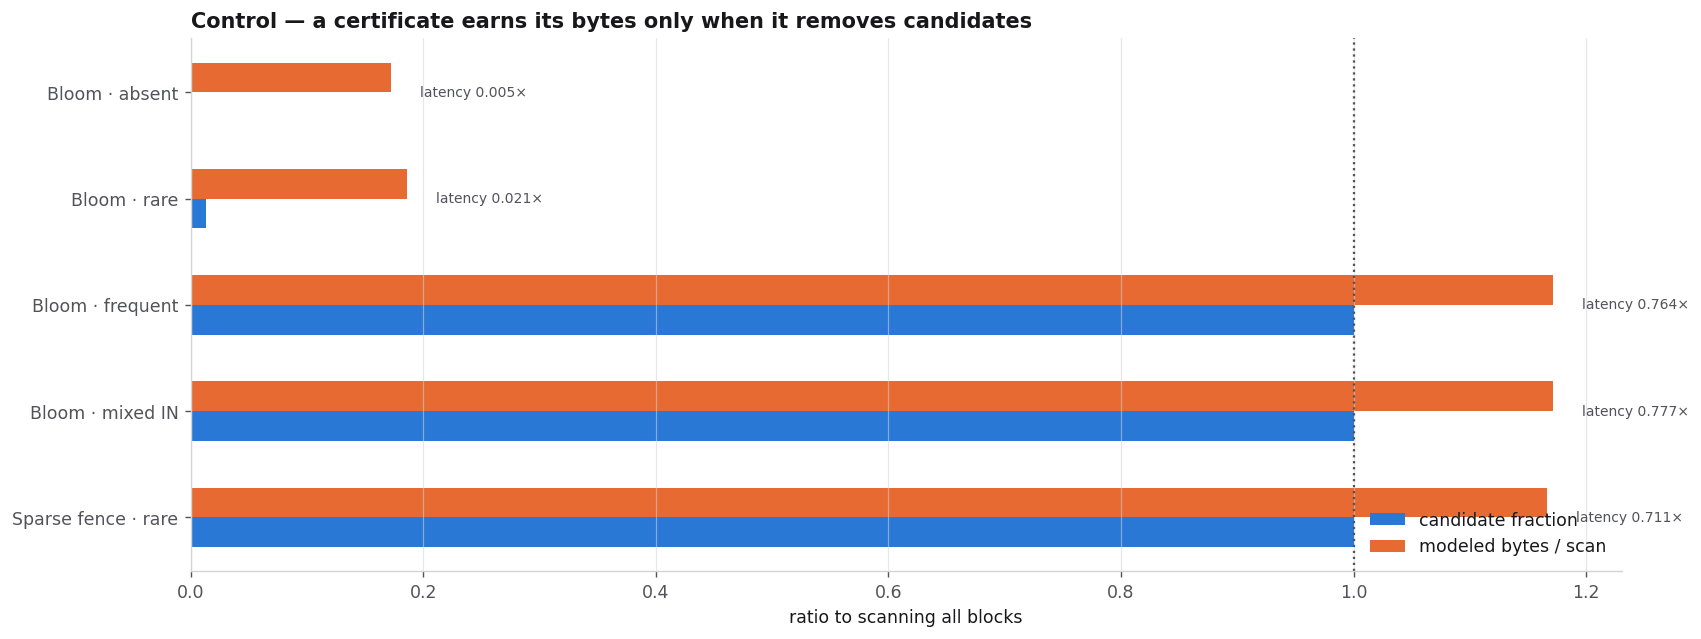

A Bloom miss is an exact empty result. A Bloom hit, min/max overlap, or fence interval is only a `CandidateBitmap`; the plan must refine it before returning rows. Frequent and mixed-IN probes select every block here, so their metadata bytes exceed a scan.

In [15]:
# Control: familiar certificates help only when they remove candidates.
cert = read_csv(RESULTS / "certificate_study/summary.csv")
wanted=[("bloom","eq_absent","Bloom · absent"),("bloom","eq_rare","Bloom · rare"),
        ("bloom","eq_frequent","Bloom · frequent"),("bloom","in_mixed","Bloom · mixed IN"),
        ("sparse_fence","eq_rare","Sparse fence · rare")]
rows=[]
for plan,query,label in wanted:
    row=next(r for r in cert if r["plan"]==plan and r["query"]==query)
    rows.append((label,float(row["candidate_fraction_median"]),
                 float(row["modeled_bytes_over_scan_median"]),
                 float(row["source_latency_ratio_median"])))

fig,ax=plt.subplots(figsize=(13.5,5.0),constrained_layout=True)
y=np.arange(len(rows)); h=0.28
ax.barh(y+h/2,[r[1] for r in rows],height=h,color=BLUE,label="candidate fraction")
ax.barh(y-h/2,[r[2] for r in rows],height=h,color=ORANGE,label="modeled bytes / scan")
ax.axvline(1,color=MUTED,ls=":",lw=1.3)
ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlabel("ratio to scanning all blocks")
ax.set_title("Control — a certificate earns its bytes only when it removes candidates",
             loc="left",weight="bold")
ax.legend(loc="lower right")
for i,row in enumerate(rows):
    ax.text(max(row[1],row[2])+0.025,i,f"latency {row[3]:.3f}×",va="center",fontsize=8,color=MUTED)
ax.grid(axis="y",visible=False)
plt.show()
display(Markdown(
    "A Bloom miss is an exact empty result. A Bloom hit, min/max overlap, or fence interval is only a "
    "`CandidateBitmap`; the plan must refine it before returning rows. Frequent and mixed-IN probes "
    "select every block here, so their metadata bytes exceed a scan."
))


**Control interpretation**

- Bloom and sparse-fence sidecars are budgeted separately; they are not credited as
  free page capabilities.
- Absent and rare probes remove most candidates and are the intended use case.
- Frequent and mixed-IN probes retain every block; metadata then adds bytes without
  removing scan work.
- Candidate-producing controls always perform exact value refinement.


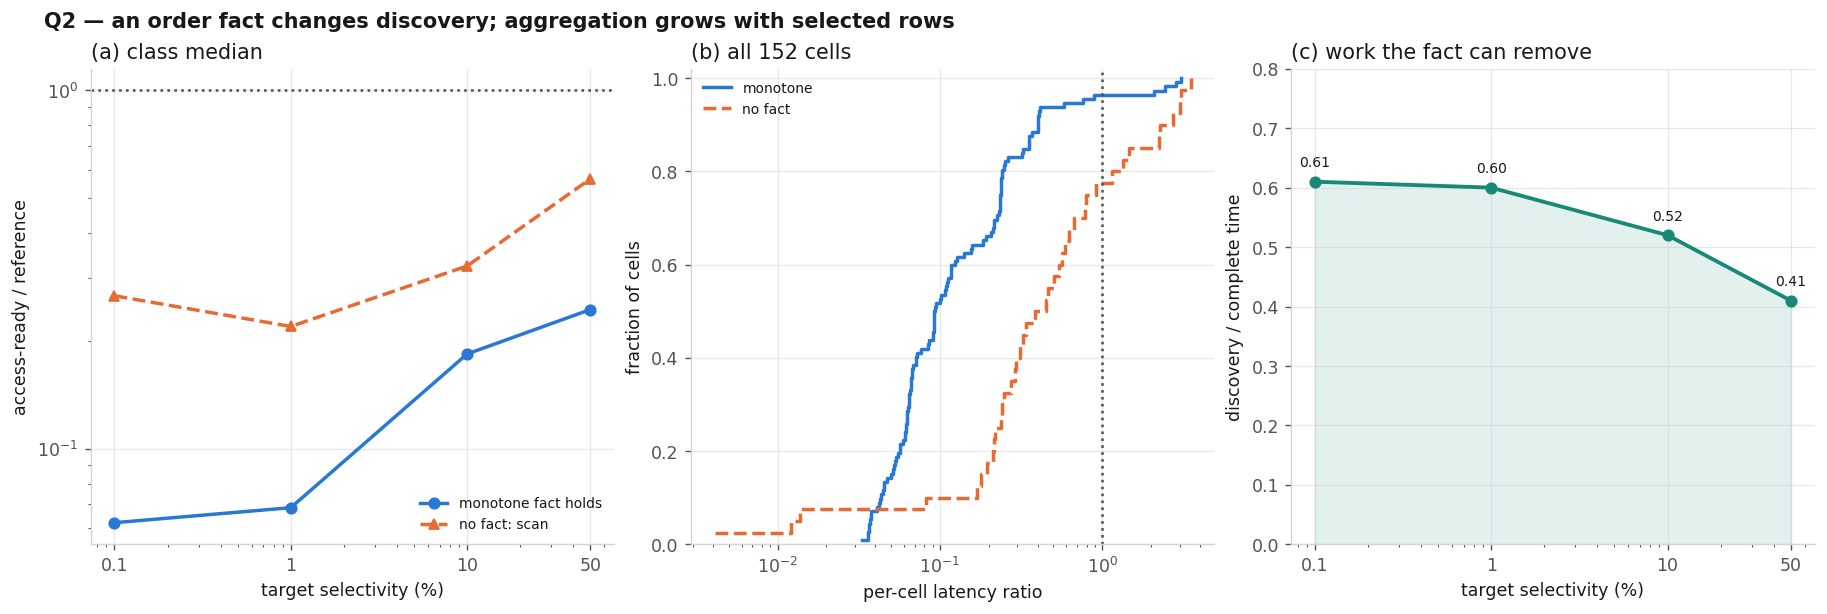

In [16]:
# Q2: the latency curves plus the discovery-share decomposition that explains their shape.
mx,my=parse_plot("WitCurveMonotonePlot"); nx,ny=parse_plot("WitCurveNoFactPlot")
mex,mey=parse_plot("WitEcdfMonotonePlot"); nex,ney=parse_plot("WitEcdfNoFactPlot")
selectivity=np.array([0.1,1,10,50])
discovery=np.array([float(claim(k)) for k in
    ["WitDiscoveryShareTenth","WitDiscoveryShareOnePct","WitDiscoveryShareTenPct","WitDiscoveryShareFiftyPct"]])

fig,(a,b,c)=plt.subplots(1,3,figsize=(14.5,4.8),constrained_layout=True)
a.plot(mx,my,"o-",color=BLUE,lw=2,label="monotone fact holds")
a.plot(nx,ny,"^--",color=ORANGE,lw=2,label="no fact: scan")
a.axhline(1,color=MUTED,ls=":"); a.set_xscale("log"); a.set_yscale("log")
a.set_xticks(selectivity,labels=["0.1","1","10","50"])
a.set_xlabel("target selectivity (%)"); a.set_ylabel("access-ready / reference")
a.set_title("(a) class median",loc="left"); a.legend(fontsize=8)

b.step(mex,mey,where="post",color=BLUE,lw=2,label="monotone")
b.step(nex,ney,where="post",color=ORANGE,lw=2,ls="--",label="no fact")
b.axvline(1,color=MUTED,ls=":"); b.set_xscale("log"); b.set_ylim(0,1.02)
b.set_xlabel("per-cell latency ratio"); b.set_ylabel("fraction of cells")
b.set_title("(b) all 152 cells",loc="left"); b.legend(fontsize=8)

c.plot(selectivity,discovery,"o-",color=TEAL,lw=2.2)
c.fill_between(selectivity,0,discovery,color=TEAL,alpha=0.12)
c.set_xscale("log"); c.set_ylim(0,0.8); c.set_xticks(selectivity,labels=["0.1","1","10","50"])
c.set_xlabel("target selectivity (%)"); c.set_ylabel("discovery / complete time")
c.set_title("(c) work the fact can remove",loc="left")
for x,yv in zip(selectivity,discovery): c.text(x,yv+0.025,f"{yv:.2f}",ha="center",fontsize=8)

fig.suptitle("Q2 — an order fact changes discovery; aggregation grows with selected rows",
             x=0.02,ha="left",weight="bold")
plt.show()


**Q2 interpretation**

- At low selectivity, the monotone class removes most predicate-discovery work.
- The advantage narrows as more rows qualify because aggregation grows with the
  result while boundary search remains small.
- The no-fact class uses the scan path and spans both sides of parity.
- The class is assigned by the encoded certificate, not by observed latency.


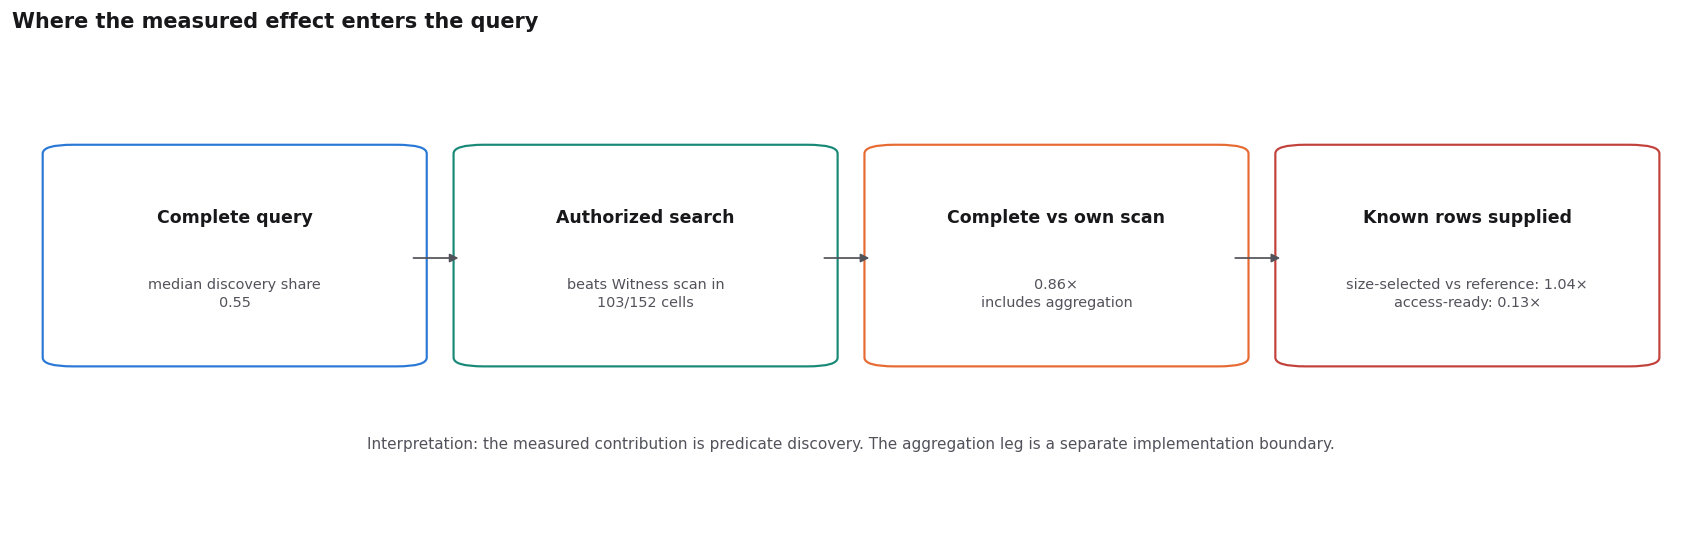

In [17]:
# Decompose the result so the notebook does not credit every gain to compressed execution.
fig,ax=plt.subplots(figsize=(13.5,4.2),constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
items=[
    ("Complete query",f"median discovery share\n{claim('WitDiscoveryShare')}",BLUE),
    ("Authorized search",f"beats Witness scan in\n{claim('WitFilterBeatsScan')}/{claim('WitCells')} cells",TEAL),
    ("Complete vs own scan",f"{claim('WitCompleteOverScan')}×\nincludes aggregation",ORANGE),
    ("Known rows supplied",f"size-selected vs reference: {claim('WitKnownOverParquet')}×\naccess-ready: {claim('WitKnownDirectOverParquet')}×",RED),
]
for i,(title,body,colour) in enumerate(items):
    x=0.03+i*0.245
    box(ax,(x,0.34),0.205,0.43,title,body,"white",colour)
    if i<len(items)-1:
        ax.annotate("",xy=(x+0.238,0.55),xytext=(x+0.207,0.55),
                    arrowprops=dict(arrowstyle="-|>",color=MUTED))
ax.text(0.5,0.16,
        "Interpretation: the measured contribution is predicate discovery. The aggregation leg is a separate implementation boundary.",
        ha="center",fontsize=8.8,color=MUTED)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("Where the measured effect enters the query",loc="left",weight="bold")
plt.show()


**Why the decomposition matters**

- A complete-query ratio mixes predicate discovery and value aggregation.
- Supplying matching rows for free isolates the aggregation leg; its behavior is not
  relabelled as a discovery contribution.
- The measured claim is therefore narrower: authorization changes how qualifying
  rows are found. It does not establish a universally faster decoder.


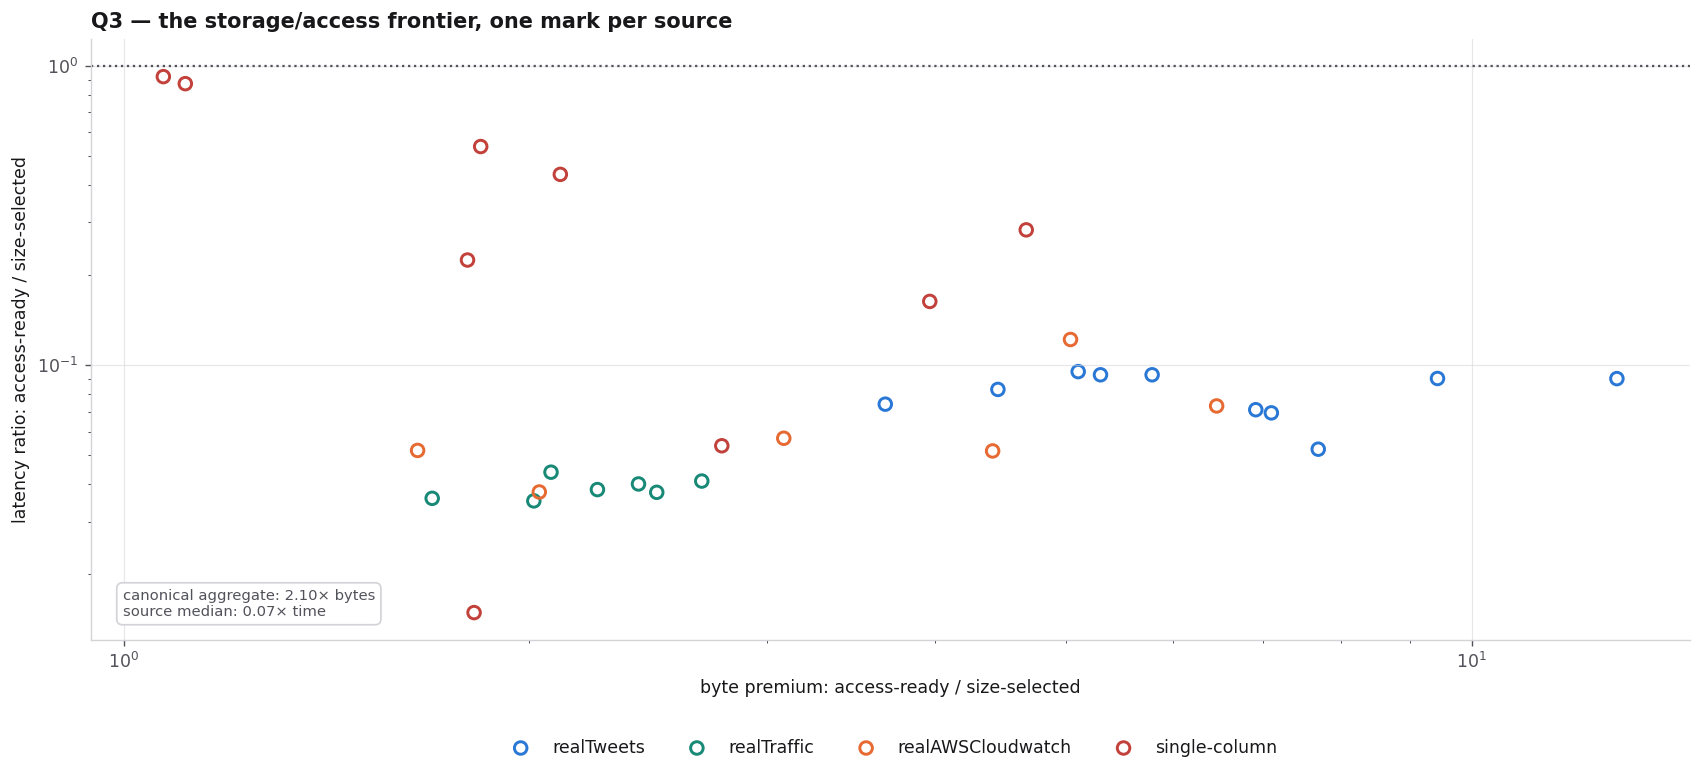

In [18]:
# Q3: reproduce the per-source storage/access frontier from source_summary.csv.
summary=read_csv(RESULTS / "predicate_pipeline/source_summary.csv")
def family(source):
    head=source.split("/")[0]
    return head if head in {"realTweets","realTraffic","realAWSCloudwatch"} else "single-column"
palette={"realTweets":BLUE,"realTraffic":TEAL,"realAWSCloudwatch":ORANGE,"single-column":RED}

fig,ax=plt.subplots(figsize=(13.5,6.1),constrained_layout=True)
for fam,colour in palette.items():
    rows=[r for r in summary if family(r["source"])==fam]
    x=[float(r["direct_gen_over_storage_gen_file_bytes_median"]) for r in rows]
    y=[float(r["complete_direct_gen_over_storage_gen_median"]) for r in rows]
    ax.scatter(x,y,s=52,facecolors="none",edgecolors=colour,lw=1.7,label=fam)
ax.axhline(1,color=MUTED,ls=":",lw=1.3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("byte premium: access-ready / size-selected")
ax.set_ylabel("latency ratio: access-ready / size-selected")
ax.set_title("Q3 — the storage/access frontier, one mark per source",loc="left",weight="bold")
ax.legend(ncol=4,loc="lower center",bbox_to_anchor=(0.5,-0.22))
ax.text(0.02,0.04,
        f"canonical aggregate: {claim('WitAccessPremium')}× bytes\nsource median: {claim('WitSourceDirectStorageMedian')}× time",
        transform=ax.transAxes,fontsize=8.5,color=MUTED,
        bbox=dict(facecolor="white",edgecolor=GRID,boxstyle="round,pad=0.4"))
plt.show()


**Q3 interpretation**

- Every mark compares two pages for the same source under the same query pipeline.
- Moving right pays more bytes to retain local access; moving down reduces selective
  query time.
- The spread is the result. A single average would hide both inexpensive wins and
  sources where extra bytes buy little.
- This is a workload-dependent physical-design choice, not a claim that one policy
  dominates all scans or all storage tiers.


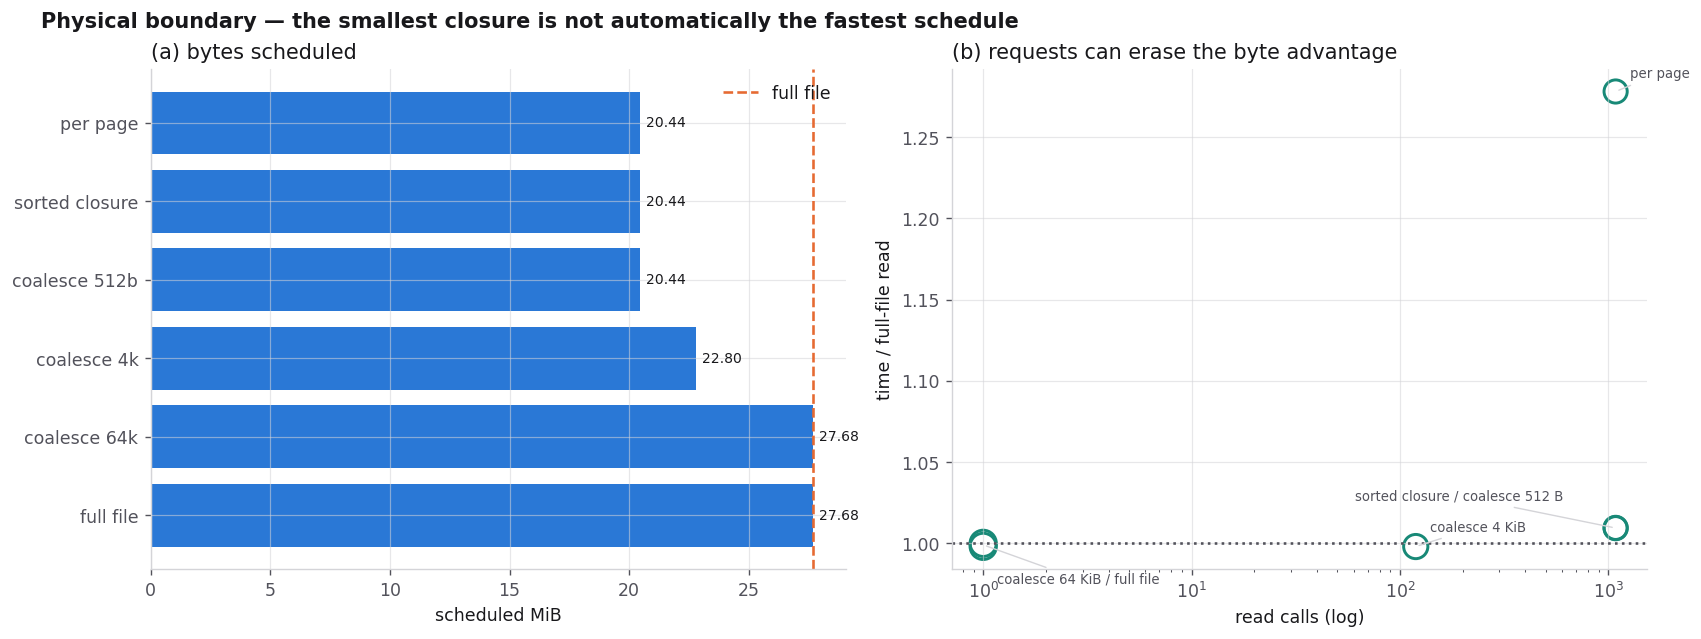

The committed control requires **20.44 MiB** from a **27.68 MiB** file. Per-page closure issues **1083** calls and takes **1.28×** a full read; 4 KiB coalescing reduces this to **119** calls and **1.00×**. This is one OS-cold XFS mechanism result, not a device-universal constant.

In [19]:
# Cold XFS control: logical closure and storage schedule are different optimization layers.
storage=read_csv(RESULTS / "real_access/storage_scan.csv")
cold=[r for r in storage if r["storage"]=="workspace_mount" and r["filesystem"]=="xfs"
      and r["order"]=="random" and r["cache_state"]=="cold"]
full=next(r for r in cold if r["policy"]=="full_file"); base=float(full["median_ns"])
policy_order=["per_page","sorted_closure","coalesce_512b","coalesce_4k","coalesce_64k","full_file"]
cold=sorted(cold,key=lambda r:policy_order.index(r["policy"]))

fig,(a,b)=plt.subplots(1,2,figsize=(13.5,5.0),constrained_layout=True)
names=[r["policy"].replace("_"," ") for r in cold]
scheduled=np.array([float(r["scheduled_bytes"])/1048576 for r in cold])
calls=np.array([int(r["read_calls"]) for r in cold])
latency=np.array([float(r["median_ns"])/base for r in cold])

bars=a.barh(names,scheduled,color=BLUE)
a.axvline(float(full["file_bytes"])/1048576,color=ORANGE,ls="--",label="full file")
a.set_xlabel("scheduled MiB"); a.set_title("(a) bytes scheduled",loc="left"); a.invert_yaxis(); a.legend()
for bar,v in zip(bars,scheduled): a.text(v+0.25,bar.get_y()+bar.get_height()/2,f"{v:.2f}",va="center",fontsize=8)

b.scatter(calls,latency,s=35+scheduled*7,facecolors="none",edgecolors=TEAL,lw=1.7)
groups = [
    ("per page", ["per page"], (8, 8)),
    ("sorted closure / coalesce 512 B", ["sorted closure", "coalesce 512b"], (-150, 16)),
    ("coalesce 4 KiB", ["coalesce 4k"], (8, 9)),
    ("coalesce 64 KiB / full file", ["coalesce 64k", "full file"], (8, -22)),
]
for label, members, offset in groups:
    idx=[names.index(name) for name in members]
    x=float(np.mean(calls[idx])); y=float(np.mean(latency[idx]))
    b.annotate(label,(x,y),xytext=offset,textcoords="offset points",fontsize=7.6,color=MUTED,
               arrowprops=dict(arrowstyle="-",color=GRID,lw=0.8))
b.axhline(1,color=MUTED,ls=":"); b.set_xscale("log")
b.set_xlabel("read calls (log)"); b.set_ylabel("time / full-file read")
b.set_title("(b) requests can erase the byte advantage",loc="left")
fig.suptitle("Physical boundary — the smallest closure is not automatically the fastest schedule",
             x=0.02,ha="left",weight="bold")
plt.show()
display(Markdown(
    f"The committed control requires **{claim('WitColdRequiredMb')} MiB** from a "
    f"**{claim('WitColdFileMb')} MiB** file. Per-page closure issues **{claim('WitColdPageCalls')}** "
    f"calls and takes **{claim('WitColdPageOverFull')}×** a full read; 4 KiB coalescing reduces this "
    f"to **{claim('WitColdCoalescedCalls')}** calls and **{claim('WitColdCoalescedOverFull')}×**. "
    "This is one OS-cold XFS mechanism result, not a device-universal constant."
))


**Cold-I/O interpretation**

- Per-page closure schedules the fewest bytes but issues 1,083 positioned reads.
- Coalescing 4 KiB gaps schedules more bytes and cuts the request count to 119.
- Logical closure is a compiler property; read coalescing is a storage-scheduler
  decision. Optimizing one does not automatically optimize the other.
- “Cold” means OS page-cache eviction with `posix_fadvise`, not eviction of the RAID
  controller's device cache.


## 5. Generality beyond one order fact

Monotonicity is the deepest measured case, but the contract would be merely a
special-purpose index if unrelated facts could not authorize unrelated plans.
The study therefore includes two smaller feasibility results:

- a sorted unique dictionary proves an order-preserving mapping, so value bounds
  translate exactly into code bounds;
- an RLE layout proves run spans, so an equality count can visit runs rather than
  rows.

Neither result is presented as broad performance evidence. The samples and timing
tiers differ, and the notebook keeps that caveat adjacent to the numbers.

Both plans reuse the same fact derivation and authorization path in
[`invariants.rs`](../../src/access_compiler/invariants.rs),
[`compiler.rs`](../../src/access_compiler/compiler.rs), and
[`interpreter.rs`](../../src/access_compiler/interpreter.rs).


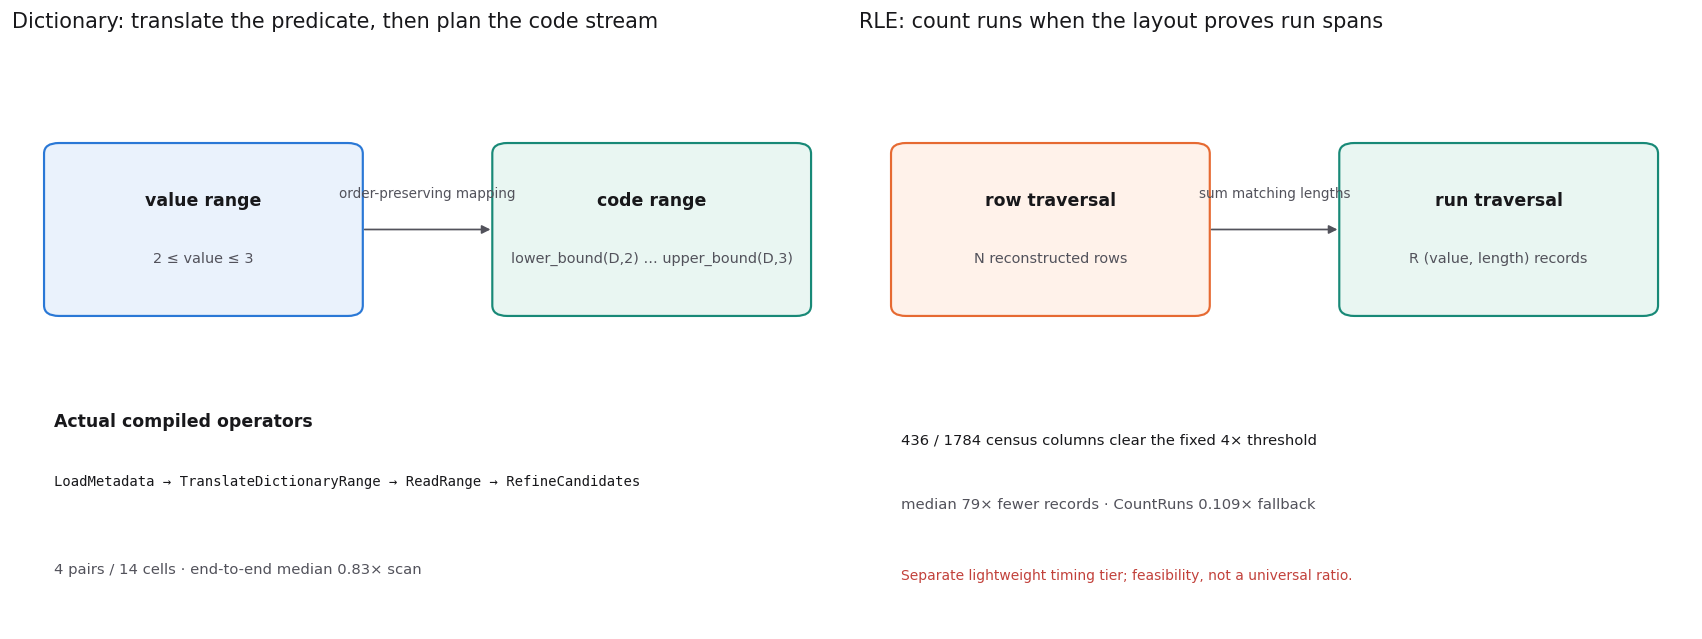

In [20]:
shuffled=[3,1,2,1,3,2,2,1,3,1,2,3]
dict_plan=witness("compile",values=shuffled,recipe="Dictionary(BitPack)",
                  query={"kind":"filter_between","low":2,"high":3})
dict_ops=[n["op"].split(" {")[0] for n in dict_plan["nodes"]]

fig,(left,right)=plt.subplots(1,2,figsize=(13.5,5.0),constrained_layout=True)
for ax in (left,right): ax.set_axis_off(); ax.grid(False)
box(left,(0.05,0.54),0.36,0.27,"value range","2 ≤ value ≤ 3","#EAF2FC",BLUE)
box(left,(0.59,0.54),0.36,0.27,"code range","lower_bound(D,2) … upper_bound(D,3)","#E9F6F2",TEAL)
left.annotate("",xy=(0.58,0.675),xytext=(0.42,0.675),
              arrowprops=dict(arrowstyle="-|>",color=MUTED))
left.text(0.50,0.73,"order-preserving mapping",ha="center",fontsize=7.8,color=MUTED,
          transform=left.transAxes)
left.text(0.05,0.34,"Actual compiled operators",weight="bold",transform=left.transAxes)
left.text(0.05,0.24," → ".join(dict_ops),family="monospace",fontsize=8,transform=left.transAxes)
left.text(0.05,0.09,
          f"{claim('WitDictPairs')} pairs / {claim('WitDictCells')} cells · end-to-end median {claim('WitDictLatency')}× scan",
          fontsize=8.5,color=MUTED,transform=left.transAxes)
left.set_title("Dictionary: translate the predicate, then plan the code stream",loc="left")

box(right,(0.05,0.54),0.36,0.27,"row traversal","N reconstructed rows","#FFF2EA",ORANGE)
box(right,(0.59,0.54),0.36,0.27,"run traversal","R (value, length) records","#E9F6F2",TEAL)
right.annotate("",xy=(0.58,0.675),xytext=(0.42,0.675),
               arrowprops=dict(arrowstyle="-|>",color=MUTED))
right.text(0.50,0.73,"sum matching lengths",ha="center",fontsize=7.8,color=MUTED,
           transform=right.transAxes)
right.text(0.05,0.31,
           f"{claim('WitRleColumns')} / {claim('WitCensusColumns')} census columns clear the fixed 4× threshold",
           fontsize=8.5,transform=right.transAxes)
right.text(0.05,0.20,
           f"median {claim('WitRleReductionMedian')}× fewer records · CountRuns {claim('WitRleLatency')}× fallback",
           fontsize=8.5,color=MUTED,transform=right.transAxes)
right.text(0.05,0.08,"Separate lightweight timing tier; feasibility, not a universal ratio.",
           fontsize=8,color=RED,transform=right.transAxes)
right.set_title("RLE: count runs when the layout proves run spans",loc="left")
plt.show()


**What the two additional plans establish**

- Dictionary translation changes value bounds into exact code bounds, but unordered
  IDs still require a scan of the code stream.
- Run-length counting replaces row visits with run-record visits only when the
  serialized representation proves those spans.
- Both plans use explicit fallbacks and answer checks.
- Their samples and timing tiers are smaller than the main study, so they establish
  feasibility rather than performance generality.


## 6. Statistical scope: what the headline can and cannot support

The 32 sources are not 32 independent draws. Several NAB files belong to the same
archive families. The study therefore reports three views of the same
source medians rather than allowing one interval to stand in for a population
claim. The forest plot below makes that sensitivity visible.


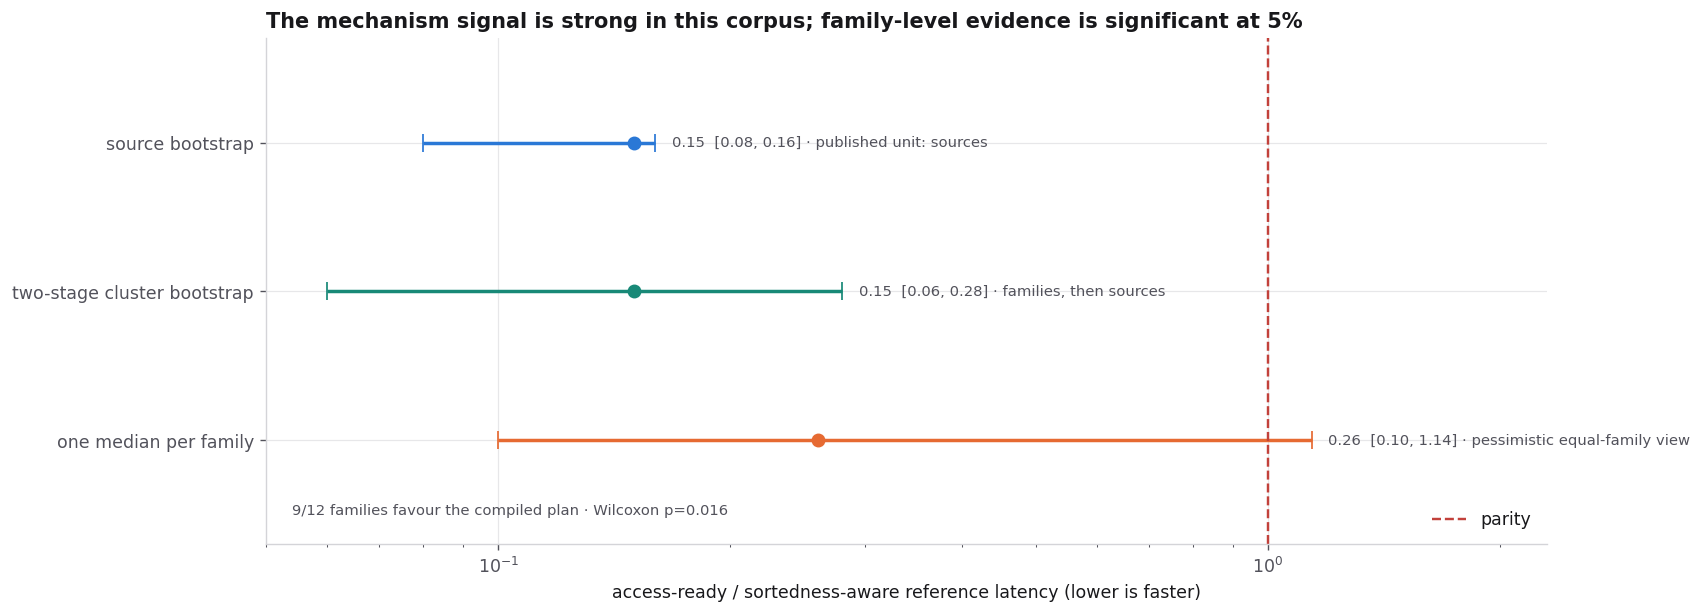

In [21]:
analyses=[
    ("source bootstrap",float(claim("WitSourceDirectBoundaryMedian")),
     float(claim("WitSourceDirectBoundaryCiLow")),float(claim("WitSourceDirectBoundaryCiHigh")),
     "published unit: sources"),
    ("two-stage cluster bootstrap",float(claim("WitClusterDirectBoundaryMedian")),
     float(claim("WitClusterDirectBoundaryCiLow")),float(claim("WitClusterDirectBoundaryCiHigh")),
     "families, then sources"),
    ("one median per family",float(claim("WitFamilyDirectBoundaryMedian")),
     float(claim("WitFamilyDirectBoundaryCiLow")),float(claim("WitFamilyDirectBoundaryCiHigh")),
     "pessimistic equal-family view"),
]
fig,ax=plt.subplots(figsize=(13.5,4.8),constrained_layout=True)
for i,(name,point,lo,hi,note) in enumerate(analyses):
    y=len(analyses)-1-i
    ax.errorbar(point,y,xerr=[[point-lo],[hi-point]],fmt="o",color=[BLUE,TEAL,ORANGE][i],
                capsize=5,lw=2,ms=7)
    ax.text(hi*1.05,y,f"{point:.2f}  [{lo:.2f}, {hi:.2f}] · {note}",va="center",fontsize=8.5,color=MUTED)
ax.axvline(1,color=RED,ls="--",lw=1.4,label="parity")
ax.set_xscale("log"); ax.set_xlim(0.05,2.3); ax.set_ylim(-0.7,2.7)
ax.set_yticks([2,1,0]); ax.set_yticklabels([a[0] for a in analyses])
ax.set_xlabel("access-ready / sortedness-aware reference latency (lower is faster)")
family_p=float(claim("WitFamilyWilcoxonP"))
ax.set_title("The mechanism signal is strong in this corpus; family-level evidence is "
             + ("significant at 5%" if family_p < 0.05 else "borderline"),
             loc="left",weight="bold")
ax.legend(loc="lower right")
ax.text(0.02,0.06,
        f"{claim('WitFamilyWins')}/{claim('WitFamilies')} families favour the compiled plan · Wilcoxon p={claim('WitFamilyWilcoxonP')}",
        transform=ax.transAxes,fontsize=8.5,color=MUTED)
plt.show()

source_rows=read_csv(RESULTS/"predicate_pipeline/source_summary.csv")
per_source=[float(r["complete_direct_gen_over_parquet_boundary_median"]) for r in source_rows]
assert round(standard_median(per_source),2)==float(claim("WitSourceDirectBoundaryMedian"))


**Statistical reading**

- The source-level and two-stage cluster intervals remain below parity for this
  corpus.
- Collapsing each archive family to one equal-weight draw crosses parity and gives a
  deliberately pessimistic sensitivity view.
- The distribution-free family test (counts and p-value printed in the figure) is the
  population-level check; read it beside the pessimistic interval.
- The evidence therefore supports a mechanism on the observed corpus, not
  population-wide superiority.


## 7. Paged columns: facts against a stored zone map

Sections 1–6 follow single pages. A real column is a sequence of pages, each encoded
on its own and proving its own facts. The paged study pages real column pairs,
runs selective `SUM(value) WHERE low ≤ selector ≤ high` queries, and plans every page
on **one executor** in five ways: from facts derived from the encoding, from an exact
stored zone map, from derived bounds alone, from the zone map plus the encoding's
shortcuts, and not at all. Every difference between them is therefore a difference in
what a planner may do, not in how fast the executor runs.

A planner gives each page the cheapest action its evidence licenses: skip, accept
every non-null row, binary search, compare dictionary codes, or scan. Before any
action runs, a checker re-reads the evidence it cites from the page.

The study driver is [`paged_study.rs`](../../src/bin/paged_study.rs); planning,
checking, and deletion live in [`paged.rs`](../../src/access_compiler/paged.rs), and
pages execute on the batch interpreter in [`vector.rs`](../../src/access_compiler/vector.rs).

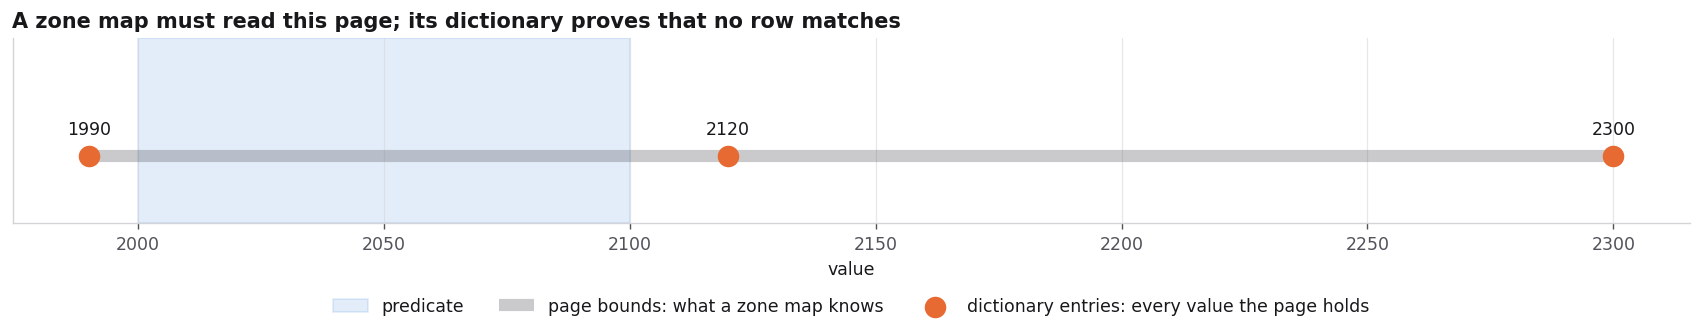

facts at the page root:
  Value(NullPlacement(NoNulls))
  Value(Bounded(TableEnds { table: FieldId(1), entries: 3 }))
  Mapping(OrderPreserving)
  Mapping(Injective)
first entry at or above 2000: 2120 > 2100 -> skip, citing the dictionary's order


In [22]:
# Example values: one page whose sorted dictionary is {1990, 2120, 2300}, and the
# predicate 2000 <= s <= 2100. The page's facts come from the live Rust bridge.
entries=[1990,2120,2300]
toy=[entries[(row*7)%3] for row in range(48)]
toy_page=witness("facts",values=toy,recipe="Dictionary(BitPack)")
root=[f["property"] for f in toy_page["facts"] if f["node"]==toy_page["root"]]
assert any("TableEnds" in p for p in root) and any("OrderPreserving" in p for p in root)
low,high=2000,2100
first=next(i for i,entry in enumerate(entries) if entry>=low)  # one binary search
fig,ax=plt.subplots(figsize=(13.5,2.5),constrained_layout=True)
ax.axvspan(low,high,color=BLUE,alpha=0.13,label="predicate")
ax.hlines(1,min(entries),max(entries),color=MUTED,lw=7,alpha=0.3,label="page bounds: what a zone map knows")
ax.scatter(entries,[1]*len(entries),s=130,color=ORANGE,zorder=3,label="dictionary entries: every value the page holds")
for entry in entries:
    ax.annotate(str(entry),(entry,1),xytext=(0,12),textcoords="offset points",ha="center")
ax.set_ylim(0.6,1.7); ax.set_yticks([]); ax.set_xlabel("value")
ax.set_title("A zone map must read this page; its dictionary proves that no row matches",loc="left",weight="bold")
ax.legend(loc="upper center",ncol=3,bbox_to_anchor=(0.5,-0.32))
plt.show()
print("facts at the page root:",*root,sep="\n  ")
print(f"first entry at or above {low}: {entries[first]} > {high} -> skip, citing the dictionary's order")

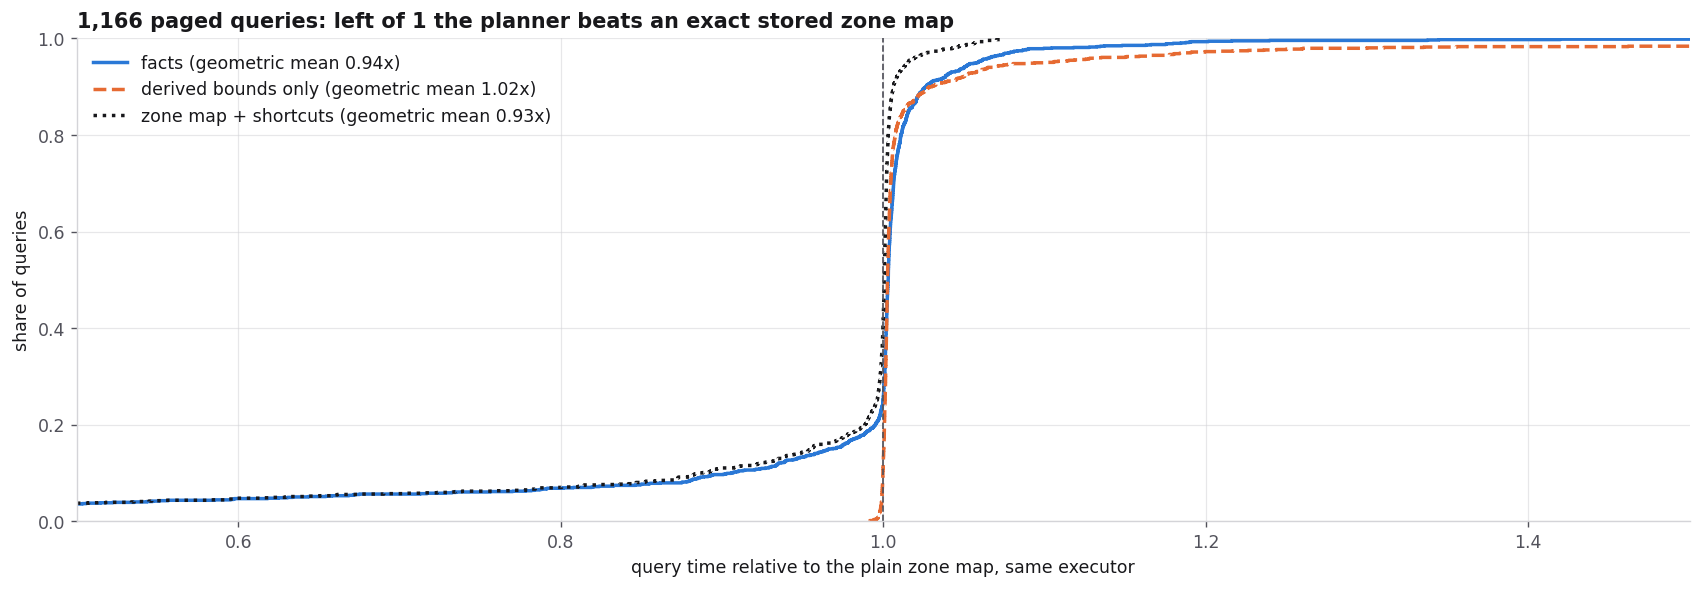

pages skipped: facts 6,757, exact zone map 5,400 (+25%), 1,519 of them because a sorted dictionary held no value in the range
facts / zone map: 0.94x, 95% interval over tables [0.88, 0.98], 0.94-0.94x across 3 runs; on the 129 queries with a dictionary skip 0.78x


In [23]:
# Every paged query, timed on one executor under each planner (canonical CSV).
PAGED=RESULTS/"paged_study"
queries={}
for row in read_csv(PAGED/"queries.csv"):
    queries.setdefault((row["pair"],row["predicate"]),{})[row["arm"]]=row
def geo(values):
    return math.exp(sum(math.log(v) for v in values)/len(values))
def against_zone_map(arm):
    return sorted(float(a[arm]["median_ns"])/float(a["witness_direct_zonemap"]["median_ns"])
                  for a in queries.values())
ratios={"facts":against_zone_map("witness_direct_facts"),
        "derived bounds only":against_zone_map("witness_direct_factbounds"),
        "zone map + shortcuts":against_zone_map("witness_direct_zonemapplus")}
assert f"{len(queries):,}"==claim("WitPagedCells")
assert f"{geo(ratios['facts']):.2f}"==claim("WitPagedFactsOverZonemapGeo")
skips={arm:sum(int(a[arm]["skipped"]) for a in queries.values())
       for arm in ("witness_direct_facts","witness_direct_zonemap")}
code_skips=sum(int(a["witness_direct_facts"]["code_skipped"]) for a in queries.values())
assert f"{code_skips:,}"==claim("WitPagedCodeSkips")

fig,ax=plt.subplots(figsize=(13.5,4.6),constrained_layout=True)
for (name,values),color,style in zip(ratios.items(),[BLUE,ORANGE,INK],["-","--",":"]):
    ax.step(values,np.arange(1,len(values)+1)/len(values),where="post",color=color,ls=style,lw=2,
            label=f"{name} (geometric mean {geo(values):.2f}x)")
ax.axvline(1,color=MUTED,ls="--",lw=1)
ax.set_xlim(0.5,1.5); ax.set_ylim(0,1)
ax.set_xlabel("query time relative to the plain zone map, same executor")
ax.set_ylabel("share of queries")
ax.set_title(f"{len(queries):,} paged queries: left of 1 the planner beats an exact stored zone map",
             loc="left",weight="bold")
ax.legend(loc="upper left")
plt.show()
print(f"pages skipped: facts {skips['witness_direct_facts']:,}, exact zone map "
      f"{skips['witness_direct_zonemap']:,} (+{claim('WitPagedFactsExtraSkipPercent')}%), "
      f"{code_skips:,} of them because a sorted dictionary held no value in the range")
print(f"facts / zone map: {claim('WitPagedFactsOverZonemapGeo')}x, 95% interval over tables "
      f"[{claim('WitPagedFactsOverZonemapGeoTableCiLow')}, {claim('WitPagedFactsOverZonemapGeoTableCiHigh')}], "
      f"{claim('WitPagedFactsOverZonemapGeoRunLow')}-{claim('WitPagedFactsOverZonemapGeoRunHigh')}x across "
      f"{claim('WitRuns')} runs; on the {claim('WitPagedCodeSkipQueries')} queries with a dictionary skip "
      f"{claim('WitPagedCodeSkipQueriesGeo')}x")

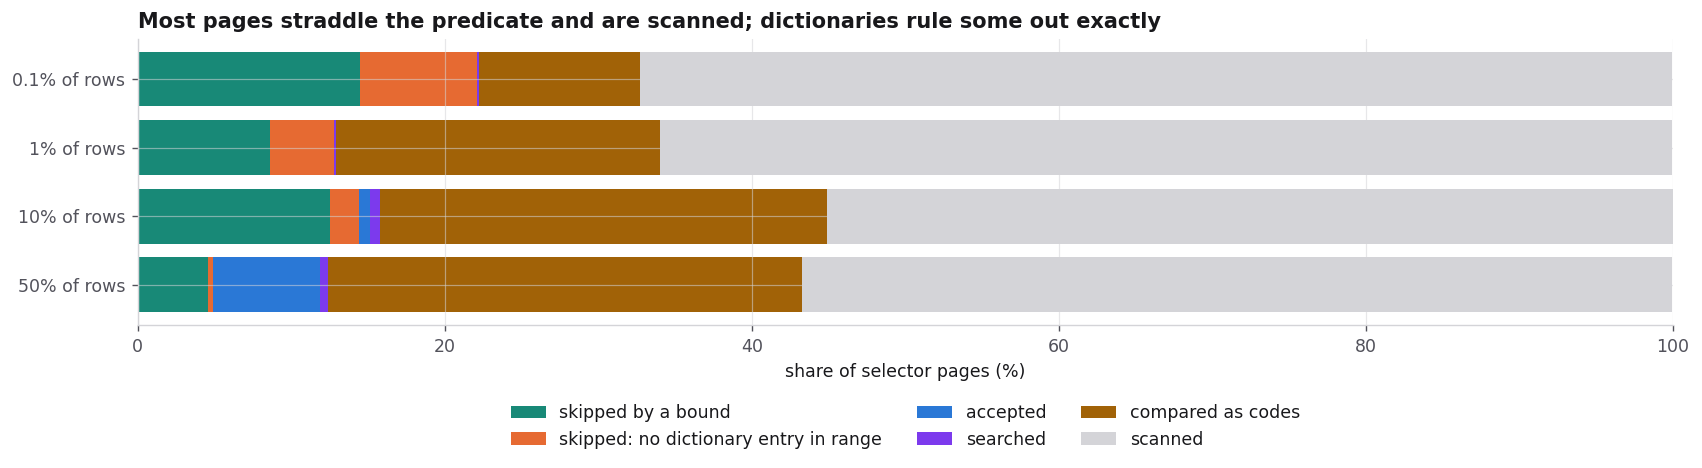

In [24]:
# How selector pages are answered, by the share of rows a predicate selects.
decisions=[]
for line in claim("WitPagedDecisionRows").split("\\\\"):
    fields=[field.strip().replace("\\%","%") for field in line.split("&")]
    if len(fields)==9:
        decisions.append(fields)
assert len(decisions)==4
labels=["skipped by a bound","skipped: no dictionary entry in range","accepted",
        "searched","compared as codes","scanned"]
colors=[TEAL,ORANGE,BLUE,"#7C3AED","#A16207",GRID]
fig,ax=plt.subplots(figsize=(13.5,3.6),constrained_layout=True)
left=np.zeros(len(decisions))
for slot,(label,color) in enumerate(zip(labels,colors)):
    share=np.array([float(row[3+slot]) for row in decisions])
    ax.barh([f"{row[0]} of rows" for row in decisions],share,left=left,color=color,label=label)
    left+=share
ax.set_xlim(0,100); ax.invert_yaxis()
ax.set_xlabel("share of selector pages (%)")
ax.set_title("Most pages straddle the predicate and are scanned; dictionaries rule some out exactly",
             loc="left",weight="bold")
ax.legend(ncol=3,loc="upper center",bbox_to_anchor=(0.5,-0.22))
plt.show()

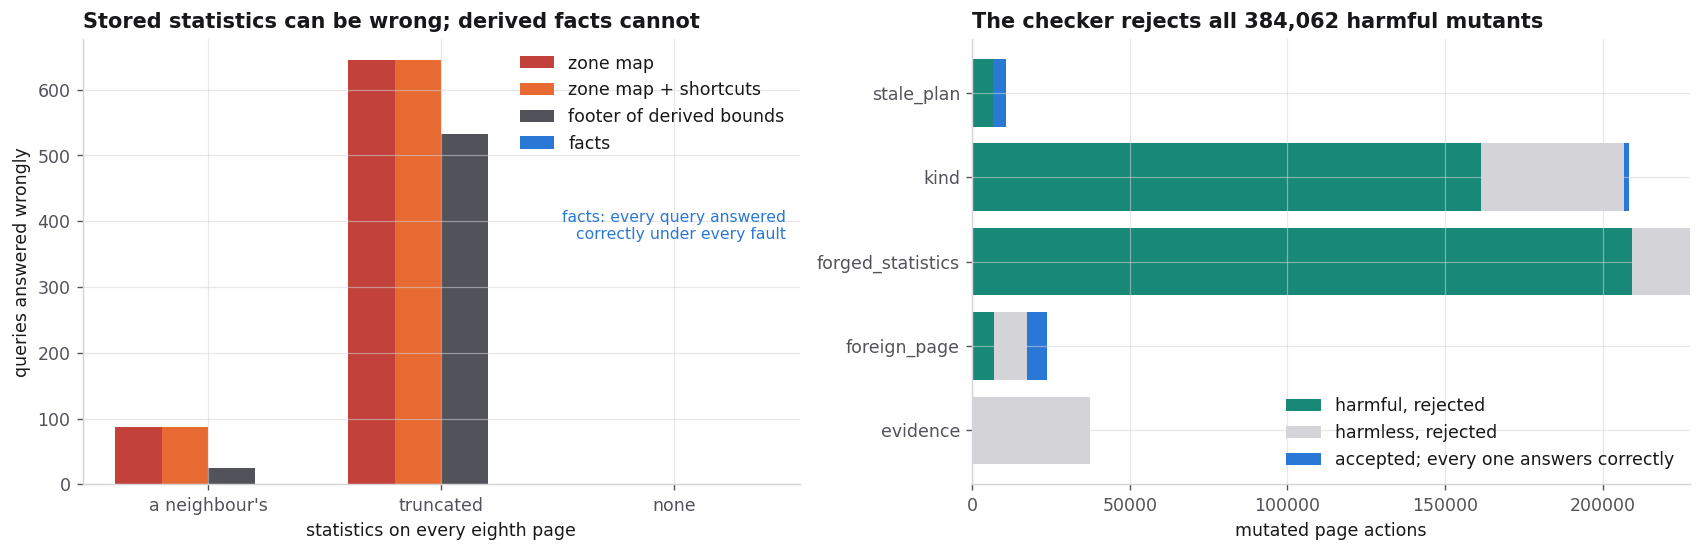

In [25]:
# Faulty statistics on every eighth page, and the plan checker under fault injection.
faults=read_csv(PAGED/"faults.csv")
kinds=[("neighbour","a neighbour's"),("truncated","truncated"),("absent","none")]
planners=[("zonemap","zone map",RED),("zonemapplus","zone map + shortcuts",ORANGE),
          ("footer","footer of derived bounds",MUTED),("facts","facts",BLUE)]
facts_wrong=sum(int(r["wrong"])+int(r["failed"]) for r in faults if r["planner"]=="facts")
checker=read_csv(PAGED/"checker.csv")
harmful=sum(int(r["mutants"]) for r in checker if r["outcome"]!="correct")
accepted_harmful=sum(int(r["mutants"]) for r in checker
                     if r["outcome"]!="correct" and r["checker"]=="accepted")
assert facts_wrong==0 and accepted_harmful==0 and f"{harmful:,}"==claim("WitCheckerHarmful")

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13.5,4.3),constrained_layout=True)
x=np.arange(len(kinds)); width=0.2
for slot,(planner,label,color) in enumerate(planners):
    wrong=[sum(int(r["wrong"]) for r in faults if r["fault"]==kind and r["planner"]==planner)
           for kind,_ in kinds]
    ax1.bar(x+(slot-1.5)*width,wrong,width,color=color,label=label)
ax1.set_xticks(x,[label for _,label in kinds]); ax1.set_xlabel("statistics on every eighth page")
ax1.set_ylabel("queries answered wrongly"); ax1.legend()
ax1.set_title("Stored statistics can be wrong; derived facts cannot",loc="left",weight="bold")
ax1.text(0.98,0.55,"facts: every query answered\ncorrectly under every fault",transform=ax1.transAxes,
         ha="right",color=BLUE,fontsize=9)
families=sorted({r["family"] for r in checker})
def tally(family,checked,harmful_only):
    return sum(int(r["mutants"]) for r in checker if r["family"]==family and r["checker"]==checked
               and ((r["outcome"]!="correct")==harmful_only))
rejected=np.array([tally(f,"rejected",True) for f in families])
harmless=np.array([tally(f,"rejected",False) for f in families])
accepted=np.array([tally(f,"accepted",False) for f in families])
ax2.barh(families,rejected,color=TEAL,label="harmful, rejected")
ax2.barh(families,harmless,left=rejected,color=GRID,label="harmless, rejected")
ax2.barh(families,accepted,left=rejected+harmless,color=BLUE,label="accepted; every one answers correctly")
ax2.set_xlabel("mutated page actions"); ax2.legend(loc="lower right")
ax2.set_title(f"The checker rejects all {harmful:,} harmful mutants",loc="left",weight="bold")
plt.show()

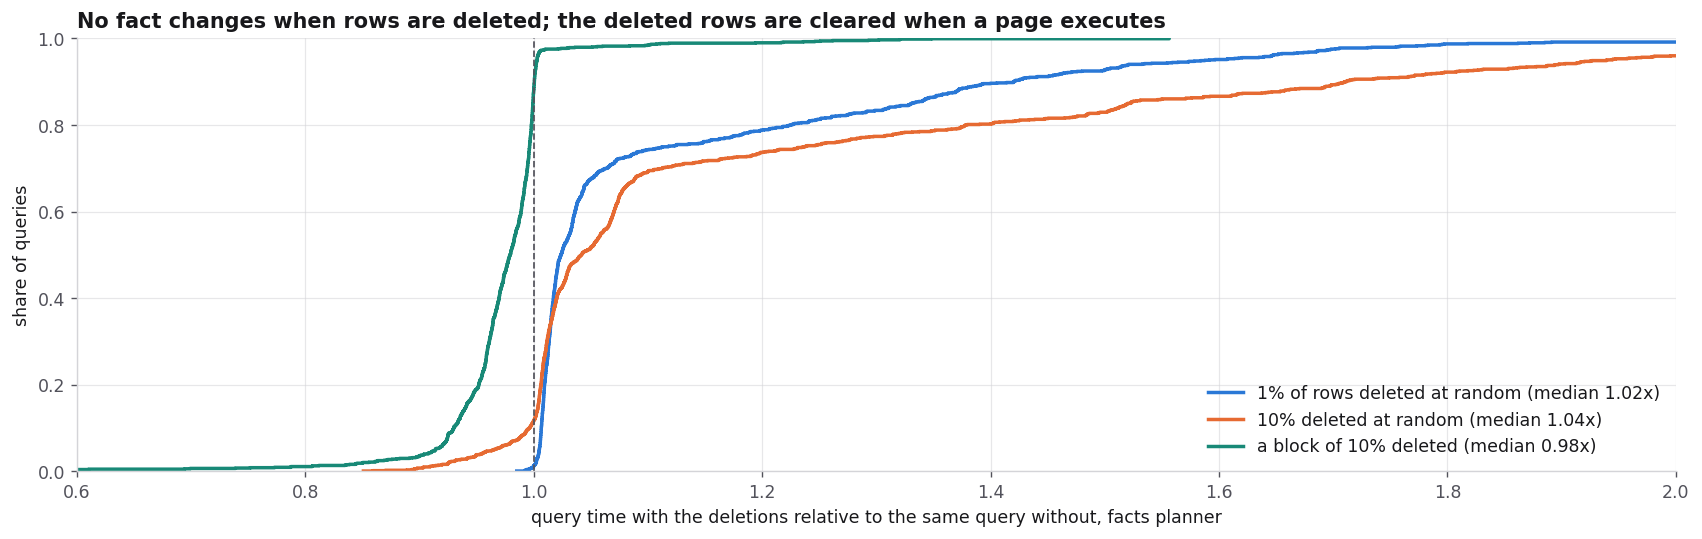

1,166 queries, every answer exact and every plan unchanged; facts take 0.95x the zone map's time with a tenth of the rows deleted


In [26]:
# Deleting rows: plans made as though nothing were deleted, executed over the rows that remain.
deletions={}
for row in read_csv(PAGED/"deletes.csv"):
    deletions.setdefault((row["pair"],row["predicate"]),{})[(row["deletion"],row["arm"])]=(
        float(row["median_ns"]),int(row["skipped"]))
plans_unchanged=all(len({v[1] for (_,arm),v in cell.items() if arm==planner})==1
                    for cell in deletions.values() for planner in ("facts","zonemap"))
assert plans_unchanged
fig,ax=plt.subplots(figsize=(13.5,4.2),constrained_layout=True)
for (deletion,label),color in zip([("random1","1% of rows deleted at random"),
                                   ("random10","10% deleted at random"),
                                   ("block10","a block of 10% deleted")],[BLUE,ORANGE,TEAL]):
    values=sorted(cell[(deletion,"facts")][0]/cell[("none","facts")][0] for cell in deletions.values())
    ax.step(values,np.arange(1,len(values)+1)/len(values),where="post",color=color,lw=2,
            label=f"{label} (median {standard_median(values):.2f}x)")
    if deletion=="random10":
        assert abs(standard_median(values)-float(claim("WitDeleteRandomTenOverNone")))<0.006
ax.axvline(1,color=MUTED,ls="--",lw=1); ax.set_xlim(0.6,2.0); ax.set_ylim(0,1)
ax.set_xlabel("query time with the deletions relative to the same query without, facts planner")
ax.set_ylabel("share of queries")
ax.set_title("No fact changes when rows are deleted; the deleted rows are cleared when a page executes",
             loc="left",weight="bold")
ax.legend(loc="lower right")
plt.show()
print(f"{len(deletions):,} queries, every answer exact and every plan unchanged; facts take "
      f"{claim('WitDeleteFactsOverZonemapRandomTenGeo')}x the zone map's time with a tenth of the rows deleted")

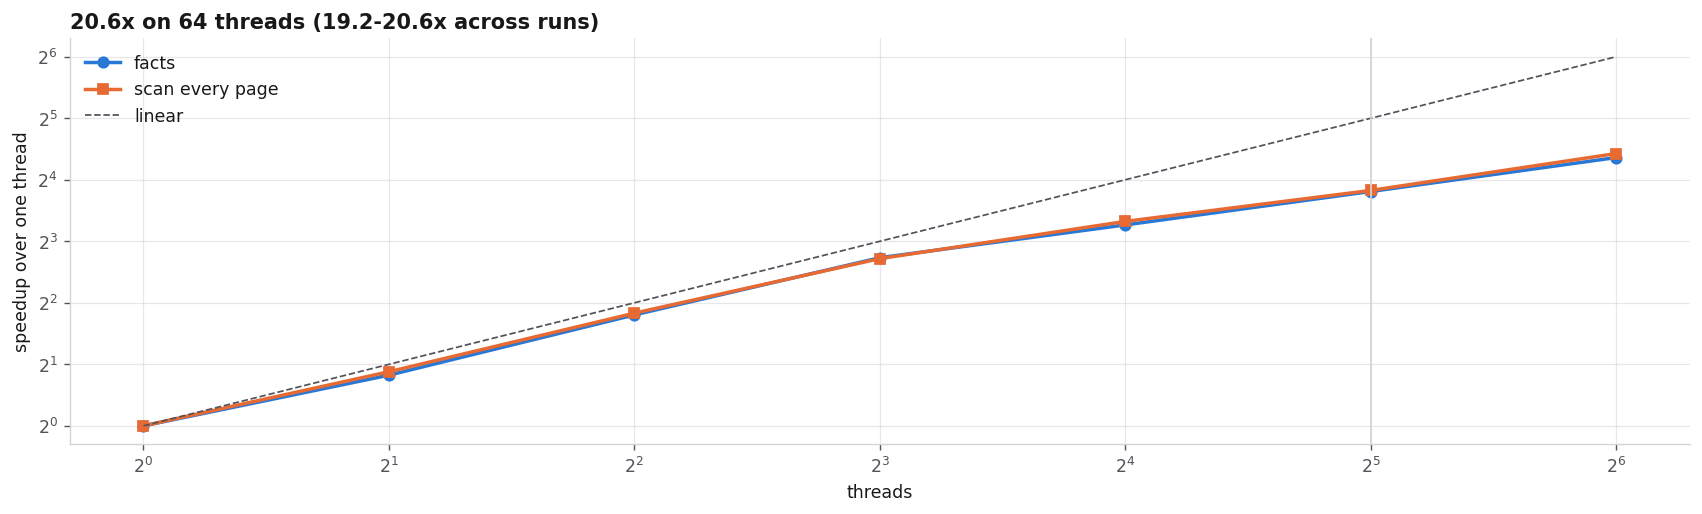

In [27]:
# Threads: the paged executor on TPC-H SF10 lineitem, 1 to 64 threads (32 physical cores).
facts_x,facts_y=parse_plot("WitScaleSpeedupPlot")
scan_x,scan_y=parse_plot("WitScaleScanSpeedupPlot")
fig,ax=plt.subplots(figsize=(13.5,4.0),constrained_layout=True)
ax.plot(facts_x,facts_y,marker="o",color=BLUE,lw=2,label="facts")
ax.plot(scan_x,scan_y,marker="s",color=ORANGE,lw=2,label="scan every page")
ax.plot(facts_x,facts_x,ls="--",color=MUTED,lw=1,label="linear")
ax.axvline(32,color=GRID,lw=1)
ax.set_xscale("log",base=2); ax.set_yscale("log",base=2)
ax.set_xlabel("threads"); ax.set_ylabel("speedup over one thread")
ax.set_title(f"{claim('WitScaleSpeedupSixtyFour')}x on 64 threads "
             f"({claim('WitScaleSpeedupSixtyFourRunLow')}-{claim('WitScaleSpeedupSixtyFourRunHigh')}x across runs)",
             loc="left",weight="bold")
ax.legend(loc="upper left")
plt.show()

**Reading the paged results**

- On one executor, planning from facts is faster than planning from an exact stored
  zone map, and skips more pages: a sorted dictionary lists every value its page holds,
  so a page whose bounds straddle the predicate can still be ruled out.
- Derived bounds alone are slightly slower than stored ones, because a
  frame-of-reference bound rounds the range up to a power of two; the encoding's
  shortcuts more than recover this.
- Wrong statistics make a zone map answer wrongly; facts derived from the page cannot
  disagree with it, and the checker turns every harmful plan mutation into an error.
- A fact holds for every row of its page, so deleting rows changes no plan; the cost is
  clearing deleted rows as each page executes.

## 8. Related work: the narrow point of difference

Witness does **not** claim that compressed execution, restart points,
dictionaries, zone maps, Bloom filters, or materialized aggregates are new.
Its narrower question is whether one typed contract can derive facts through
composed layouts, require every non-scan plan to cite sufficient evidence, close
that plan over physical bytes, and fall back explicitly when the evidence is
absent.


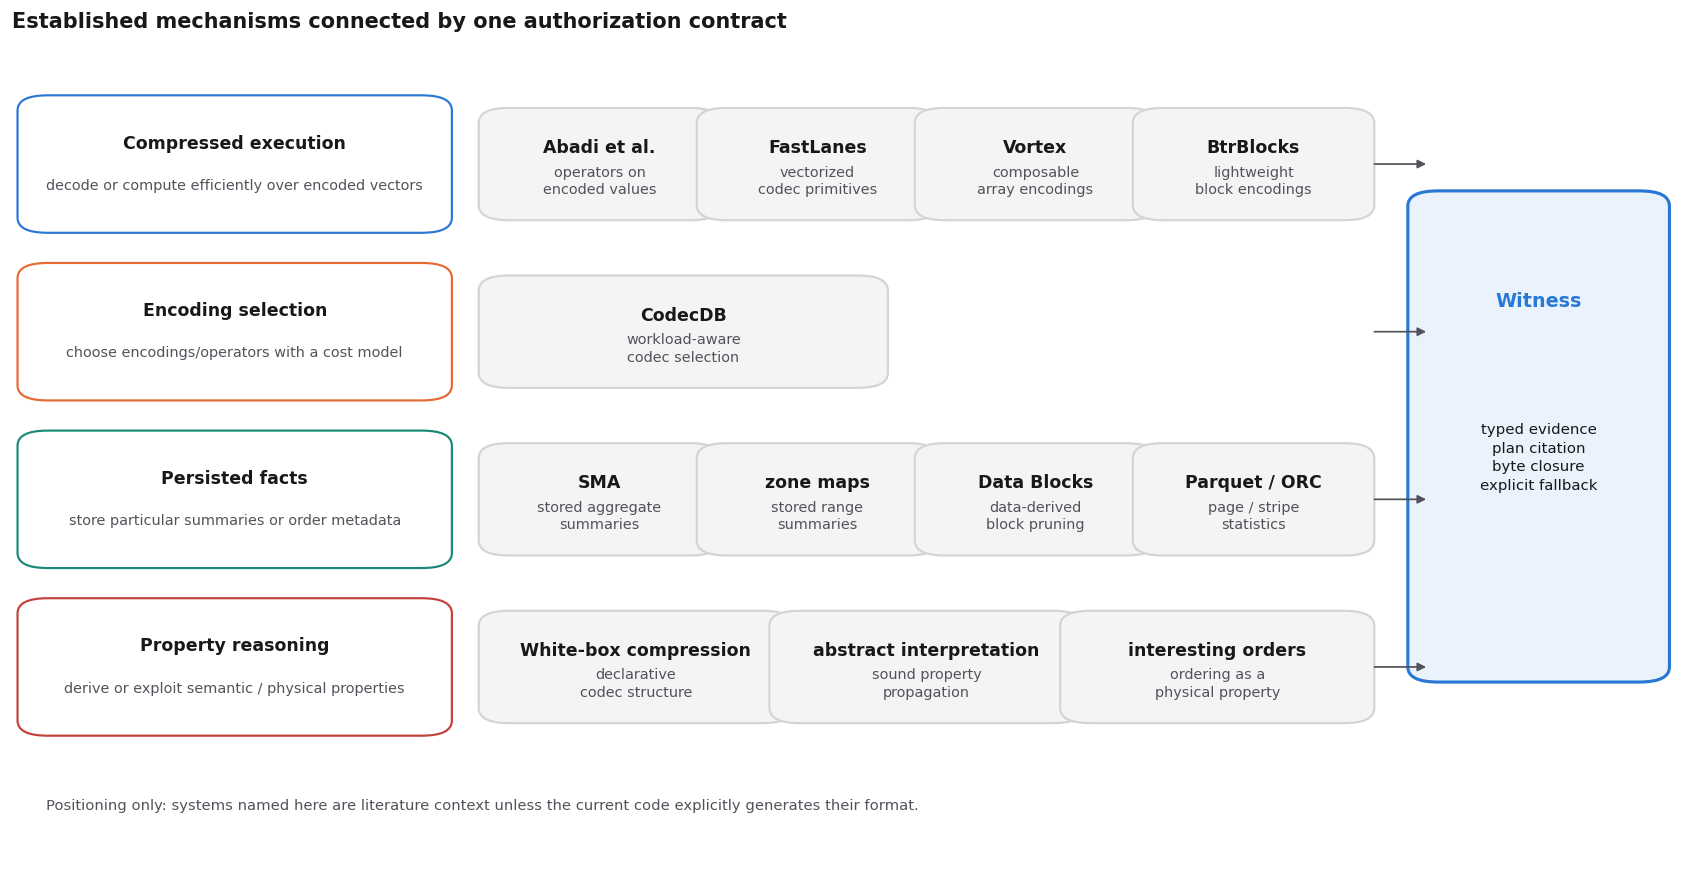

In [28]:
# Conceptual positioning. This is not a performance comparison.
lanes=[
    ("Compressed execution",[
        ("Abadi et al.", "operators on\nencoded values"),
        ("FastLanes", "vectorized\ncodec primitives"),
        ("Vortex", "composable\narray encodings"),
        ("BtrBlocks", "lightweight\nblock encodings"),
     ],BLUE,
     "decode or compute efficiently over encoded vectors"),
    ("Encoding selection",[("CodecDB", "workload-aware\ncodec selection")],ORANGE,
     "choose encodings/operators with a cost model"),
    ("Persisted facts",[
        ("SMA", "stored aggregate\nsummaries"),
        ("zone maps", "stored range\nsummaries"),
        ("Data Blocks", "data-derived\nblock pruning"),
        ("Parquet / ORC", "page / stripe\nstatistics"),
     ],TEAL,
     "store particular summaries or order metadata"),
    ("Property reasoning",[
        ("White-box compression", "declarative\ncodec structure"),
        ("abstract interpretation", "sound property\npropagation"),
        ("interesting orders", "ordering as a\nphysical property"),
     ],RED,
     "derive or exploit semantic / physical properties"),
]
fig,ax=plt.subplots(figsize=(13.5,7.0),constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
for i,(title,names,colour,note) in enumerate(lanes):
    y=0.78-i*0.20
    box(ax,(0.015,y),0.235,0.14,title,note,"white",colour)
    left, right, gap = 0.29, 0.80, 0.010
    width = min(0.22, (right-left-gap*(len(names)-1))/len(names))
    for j,(name,description) in enumerate(names):
        x=left+j*(width+gap)
        box(ax,(x,y+0.015),width,0.11,name,description,PALE,GRID)
    ax.annotate("",xy=(0.845,y+0.07),xytext=(right+0.01,y+0.07),
                arrowprops=dict(arrowstyle="-|>",color=MUTED,lw=1.0))
ax.add_patch(mpl.patches.FancyBboxPatch((0.85,0.25),0.12,0.55,
             boxstyle="round,pad=0.018",facecolor="#EAF2FC",edgecolor=BLUE,lw=1.8))
ax.text(0.91,0.68,"Witness",ha="center",weight="bold",color=BLUE,fontsize=11)
ax.text(0.91,0.50,"typed evidence\nplan citation\nbyte closure\nexplicit fallback",
        ha="center",va="center",fontsize=8.6,linespacing=1.45)
ax.text(0.02,0.08,
        "Positioning only: systems named here are literature context unless the current code explicitly generates their format.",
        fontsize=8.5,color=MUTED)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("Established mechanisms connected by one authorization contract",
             loc="left",weight="bold")
plt.show()


**Positioning**

- Compressed execution and composable layouts supply the execution substrate.
- Encoding-selection systems establish that workload-aware physical design matters.
- SMA, zone maps, Data Blocks, Parquet, and ORC demonstrate the value of persisted
  facts and indexes.
- Witness studies the narrower combination of typed evidence, plan citation,
  physical byte closure, and explicit fallback. The diagram makes no local timing
  claim about literature-only systems.


## 9. Limitations and outlook

The mechanism currently covers exact integers, seven codec primitives, three fact
families, one generated plan language, and a single-threaded Rust demonstrator.
Important boundaries remain:

- checked facts trust the encoder plus a checksummed descriptor; the checksum
  authenticates bytes, not truth;
- primary timings use resident buffers, while the cold-I/O control is one XFS host;
- no floating-point ordering under NaNs, joins, group-by, top-k, updates,
  multi-predicate planning, SIMD-tuned readers, NVMe, or object storage is claimed;
- `SUM` always performs fused encoded traversal; no aggregate certificate exists,
  so it is never answered from metadata alone;
- the finite codec menu and plan grammar do not imply globally optimal programs.

These limits are part of the result. When evidence or access is insufficient, a
recorded scan is the intended output.

The complete boundary is maintained in [`LIMITATIONS.md`](../LIMITATIONS.md).
Physical coalescing is isolated in
[`schedule.rs`](../../src/access_compiler/schedule.rs); workload-sensitive selection
is represented, but not solved globally, in
[`cost_model.rs`](../../src/access_compiler/cost_model.rs).


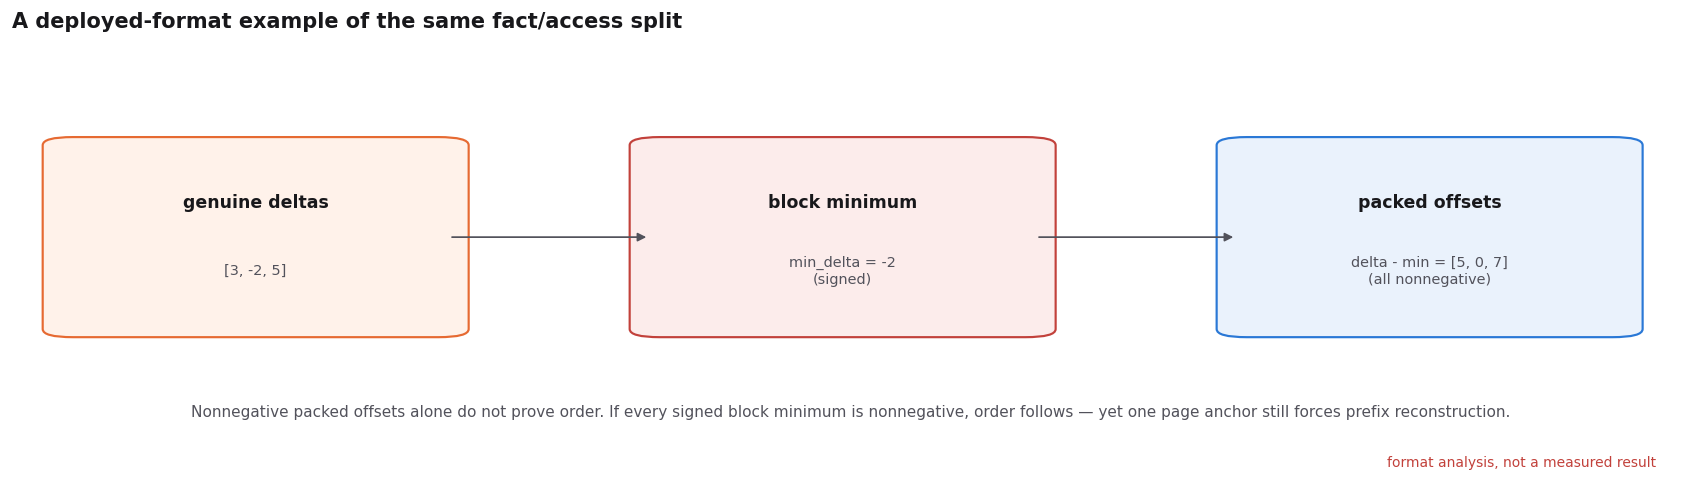

In [29]:
# Format analysis: nonnegative FOR offsets are not genuine deltas.
deltas=np.array([3,-2,5]); minimum=int(deltas.min()); offsets=deltas-minimum
fig,ax=plt.subplots(figsize=(13.5,3.9),constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
box(ax,(0.03,0.35),0.23,0.42,"genuine deltas",str(deltas.tolist()),"#FFF2EA",ORANGE)
box(ax,(0.38,0.35),0.23,0.42,"block minimum",f"min_delta = {minimum}\n(signed)","#FCECEB",RED)
box(ax,(0.73,0.35),0.23,0.42,"packed offsets",f"delta - min = {offsets.tolist()}\n(all nonnegative)","#EAF2FC",BLUE)
for a,b in [(0.26,0.38),(0.61,0.73)]:
    ax.annotate("",xy=(b,0.56),xytext=(a,0.56),arrowprops=dict(arrowstyle="-|>",color=MUTED))
ax.text(0.5,0.16,
        "Nonnegative packed offsets alone do not prove order. If every signed block minimum is nonnegative, order follows — yet one page anchor still forces prefix reconstruction.",
        ha="center",fontsize=8.8,color=MUTED)
ax.text(0.98,0.05,"format analysis, not a measured result",ha="right",fontsize=8,color=RED)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("A deployed-format example of the same fact/access split",
             loc="left",weight="bold")
plt.show()


**Why the deployed-format example belongs in the limitations section**

- Packed residuals are nonnegative because they are normalized by a signed block
  minimum; their sign alone proves nothing about original delta direction.
- Nonnegative block minima can establish within-page order as a reader-side metadata
  check.
- One absolute page anchor still makes a random row require prefix reconstruction.
- This supports the distinction between available evidence and spendable access, but
  it is format analysis rather than a measured notebook result.


## 10. Conclusion: the decision rule

The claim reduces to a conservative compiler decision:

1. derive only facts entailed by the decoder, layout, checked descriptor, and
   stated assumptions;
2. choose a non-scan operator only when a sufficient fact authorizes it;
3. close that operator over physical prerequisites and estimate the delivered
   work;
4. refine candidate guarantees before returning exact answers;
5. use fused scan/decode when the evidence or cost case is absent.

The empirical result is conditional, not universal: useful evidence removes work
when it is present and cheap to reach; preserving that access costs bytes; storage
scheduling can erase the logical advantage. Across pages, the same rule lets a
planner do without a stored zone map, skip pages a zone map must read, and keep
every plan sound when rows are deleted.


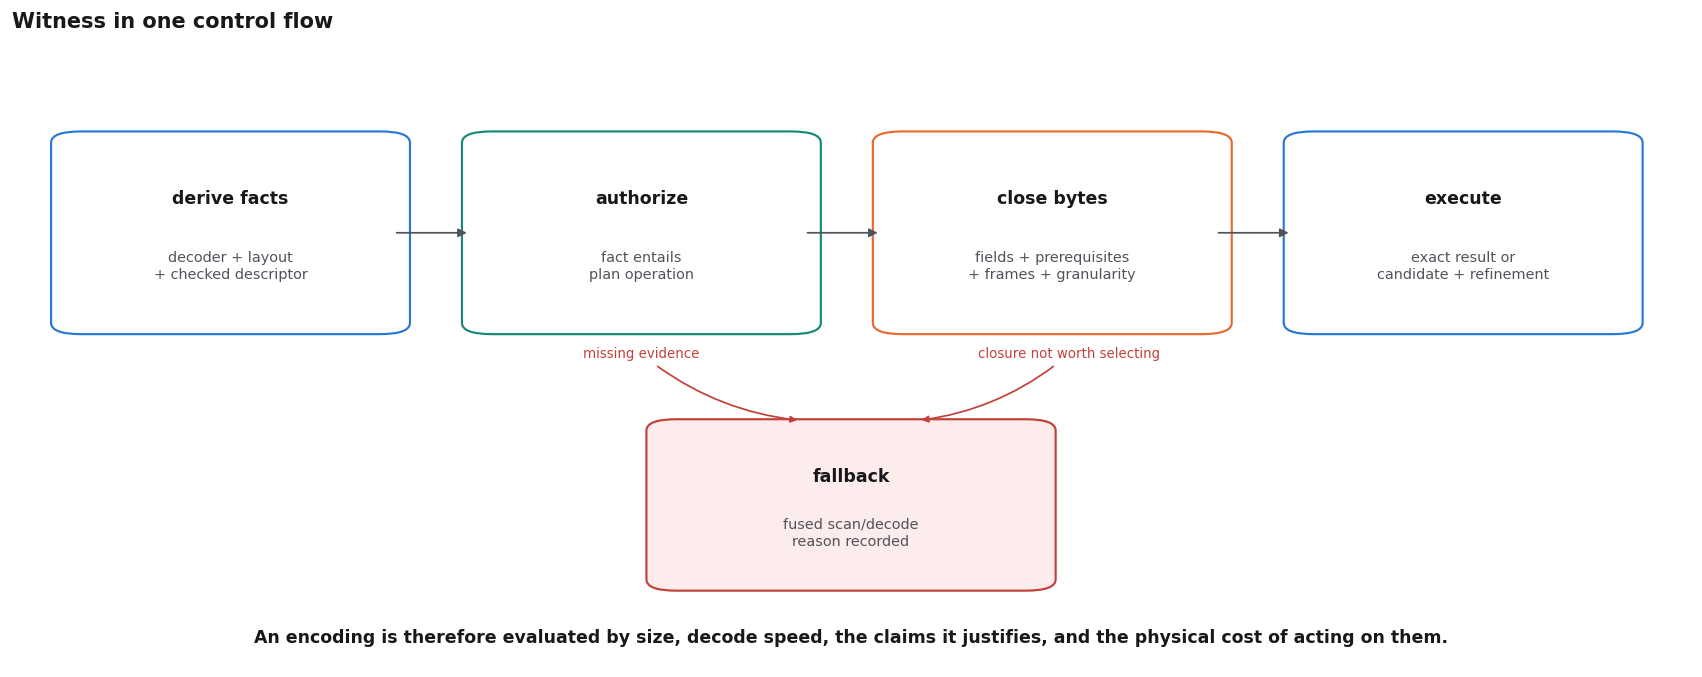

In [30]:
fig,ax=plt.subplots(figsize=(13.5,5.3),constrained_layout=True)
ax.set_axis_off(); ax.grid(False)
steps=[
    ("derive facts","decoder + layout\n+ checked descriptor",BLUE),
    ("authorize","fact entails\nplan operation",TEAL),
    ("close bytes","fields + prerequisites\n+ frames + granularity",ORANGE),
    ("execute","exact result or\ncandidate + refinement",BLUE),
]
for i,(title,body,colour) in enumerate(steps):
    x=0.035+i*0.245
    box(ax,(x,0.54),0.19,0.30,title,body,"white",colour)
    if i<len(steps)-1:
        ax.annotate("",xy=(x+0.238,0.69),xytext=(x+0.192,0.69),
                    arrowprops=dict(arrowstyle="-|>",color=MUTED))
box(ax,(0.39,0.13),0.22,0.25,"fallback","fused scan/decode\nreason recorded","#FCECEB",RED)
ax.annotate("missing evidence",xy=(0.47,0.39),xytext=(0.375,0.49),
            ha="center",fontsize=7.7,color=RED,
            arrowprops=dict(arrowstyle="-|>",color=RED,connectionstyle="arc3,rad=0.15"))
ax.annotate("closure not worth selecting",xy=(0.54,0.39),xytext=(0.63,0.49),
            ha="center",fontsize=7.7,color=RED,
            arrowprops=dict(arrowstyle="-|>",color=RED,connectionstyle="arc3,rad=-0.15"))
ax.text(0.5,0.035,
        "An encoding is therefore evaluated by size, decode speed, the claims it justifies, and the physical cost of acting on them.",
        ha="center",weight="bold",color=INK)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title("Witness in one control flow",loc="left",weight="bold")
plt.show()


**Final reading**

- Correctness comes first: an optimization is selectable only after authorization.
- Physical closure and the workload decide whether an authorized path is worth
  selecting.
- Candidate guarantees must be refined; exact guarantees may return directly.
- A fused scan/decode is a normal compiler result when facts are absent or access is
  uneconomic.


## Reproducibility and drift audit

This final cell checks the concrete dependencies used throughout the notebook:

- every referenced source path exists in the current tree;
- the live Rust bridge returns the worked example's exact rows and aggregate;
- the full Rust test suite passes;
- canonical result files reproduce the displayed source-level point estimate;
- the paged results reproduce their manifest values, and no deletion changed a
  plan.

Remeasuring every timing is intentionally separate: `./reproduce.sh` fetches and
checks inputs, reruns claim-bearing studies, regenerates the claim manifest, and
records environment-specific timings.


In [31]:
checks=[]
checks.append(("canonical evidence present",not missing))
checks.append(("current Rust filter answer",selector_run["answer"]["ranges"]==[[3,7]]))
checks.append(("current Rust selected SUM",value_run["answer"]["value"]==49))
checks.append(("referenced code paths exist",all((ROOT/p).exists() for p in paths)))
notebook=ROOT/"docs/notebooks/witness_companion.ipynb"
link_targets={target for cell in json.loads(notebook.read_text())["cells"] if cell["cell_type"]=="markdown"
              for target in re.findall(r"\]\((\.\./[^)#]+)", "".join(cell["source"]))}
checks.append(("notebook links resolve",all((notebook.parent/t).resolve().exists() for t in link_targets)))
checks.append(("source median matches manifest",
               round(standard_median(per_source),2)==float(claim("WitSourceDirectBoundaryMedian"))))

for row in formats:
    artifact=GENERATED/row["artifact"]
    if artifact.suffix == ".tsv":
        with artifact.open(newline="") as handle:
            manifest_rows=list(csv.DictReader(handle,delimiter="\t"))
        total=next(r for r in manifest_rows if r["column"]=="TOTAL")
        members=[r for r in manifest_rows if r["column"]!="TOTAL"]
        valid_total=int(total["bytes"])==int(row["bytes"])
        valid_members=all((artifact.parent/r["artifact"]).stat().st_size==int(r["bytes"])
                          for r in members)
        checks.append((f"manifest + members: {artifact.name}",valid_total and valid_members))
    else:
        checks.append((f"file size: {artifact.name}",artifact.stat().st_size==int(row["bytes"])))

tests=subprocess.run(["cargo","test","--locked","--all-features","--quiet"],
                     cwd=ROOT,capture_output=True,text=True)
checks.append(("Rust test suite",tests.returncode==0))

checks.append(("paged facts / zone map matches manifest",
               f"{geo(ratios['facts']):.2f}"==claim("WitPagedFactsOverZonemapGeo")))
checks.append(("dictionary skips match manifest",f"{code_skips:,}"==claim("WitPagedCodeSkips")))
checks.append(("no deletion changed a plan",plans_unchanged))
checks.append(("facts never wrong under faulty statistics",facts_wrong==0))
checks.append(("checker rejected every harmful mutant",accepted_harmful==0))

width=max(len(name) for name,_ in checks)
for name,ok in checks:
    print(f"{'PASS' if ok else 'FAIL':4s}  {name:<{width}s}")
assert all(ok for _,ok in checks),"one or more companion checks failed"
print(f"\n{len(checks)}/{len(checks)} checks passed")
print(f"run identity: crate {claim('WitCrateVersion')} · rules {claim('WitRuleFingerprint')}")
print("full remeasurement: ./reproduce.sh")


PASS  canonical evidence present                  
PASS  current Rust filter answer                  
PASS  current Rust selected SUM                   
PASS  referenced code paths exist                 
PASS  notebook links resolve                      
PASS  source median matches manifest              
PASS  file size: example.orc                      
PASS  manifest + members: rawi64-zstd.manifest.tsv
PASS  manifest + members: pcodec.manifest.tsv     
PASS  file size: example.csv                      
PASS  manifest + members: rawi64.manifest.tsv     
PASS  file size: example.delta-zstd.parquet       
PASS  file size: example.dictionary-snappy.parquet
PASS  manifest + members: witness.manifest.tsv    
PASS  Rust test suite                             
PASS  paged facts / zone map matches manifest     
PASS  dictionary skips match manifest             
PASS  no deletion changed a plan                  
PASS  facts never wrong under faulty statistics   
PASS  checker rejected every ha